In [2]:
import os
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

PROJECT_ROOT = Path.cwd().parent

project_dir = (
    PROJECT_ROOT /
    "DS-02_Demand_Forecasting_and_Inventory_Optimization"
)

data_dir = project_dir / "data"
raw_dir = data_dir / "raw"
processed_dir = data_dir / "processed"
models_dir = project_dir / "models"
outputs_dir = project_dir / "outputs"
app_dir = project_dir / "app"

for folder in [
    raw_dir,
    processed_dir,
    models_dir,
    outputs_dir,
    app_dir
]:
    folder.mkdir(parents=True, exist_ok=True)

print("Python:", sys.version)
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Project directory:", project_dir)
print("Project setup completed!")

Python: 3.11.9 (tags/v3.11.9:de54cf5, Apr  2 2024, 10:12:12) [MSC v.1938 64 bit (AMD64)]
Pandas: 2.3.3
NumPy: 2.4.6
Project directory: c:\Projects\Nexvia-Technologies-Data-Science-Internship\DS-02_Demand_Forecasting_and_Inventory_Optimization
Project setup completed!


In [3]:
%pip install kaggle

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
import kaggle
print("Kaggle package installed successfully!")

Kaggle package installed successfully!


In [5]:
!kaggle competitions list

HTTPSConnectionPool(host='api.kaggle.com', port=443): Max retries exceeded with url: /v1/competitions.CompetitionApiService/ListCompetitions (Caused by NameResolutionError("HTTPSConnection(host='api.kaggle.com', port=443): Failed to resolve 'api.kaggle.com' ([Errno 11001] getaddrinfo failed)"))


In [6]:
from pathlib import Path

project_dir = Path.cwd().parent / "DS-02_Demand_Forecasting_and_Inventory_Optimization"
raw_dir = project_dir / "data" / "raw"
raw_dir.mkdir(parents=True, exist_ok=True)

!kaggle competitions download -c m5-forecasting-accuracy -p "{raw_dir}"

m5-forecasting-accuracy.zip: Skipping, found more recently modified local copy (use --force to force download)


In [7]:
import zipfile

zip_path = raw_dir / "m5-forecasting-accuracy.zip"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(raw_dir)

print("Extraction completed!")
print("\nDataset files:")

for file in raw_dir.iterdir():
    print(f"{file.name} — {file.stat().st_size / (1024**2):.2f} MB")

Extraction completed!

Dataset files:
calendar.csv — 0.10 MB
m5-forecasting-accuracy.zip — 45.79 MB
sales_train_evaluation.csv — 116.10 MB
sales_train_validation.csv — 114.45 MB
sample_submission.csv — 4.99 MB
sell_prices.csv — 193.97 MB


In [8]:
import pandas as pd

files = [
    "sales_train_validation.csv",
    "sales_train_evaluation.csv",
    "calendar.csv",
    "sell_prices.csv",
    "sample_submission.csv"
]

for filename in files:
    file_path = raw_dir / filename
    df_info = pd.read_csv(file_path, nrows=5)

    print(f"\n{filename}")
    print("Columns:", len(df_info.columns))
    print("Sample shape:", df_info.shape)
    print("First columns:", df_info.columns[:8].tolist())


sales_train_validation.csv
Columns: 1919
Sample shape: (5, 1919)
First columns: ['id', 'item_id', 'dept_id', 'cat_id', 'store_id', 'state_id', 'd_1', 'd_2']

sales_train_evaluation.csv
Columns: 1947
Sample shape: (5, 1947)
First columns: ['id', 'item_id', 'dept_id', 'cat_id', 'store_id', 'state_id', 'd_1', 'd_2']

calendar.csv
Columns: 14
Sample shape: (5, 14)
First columns: ['date', 'wm_yr_wk', 'weekday', 'wday', 'month', 'year', 'd', 'event_name_1']

sell_prices.csv
Columns: 4
Sample shape: (5, 4)
First columns: ['store_id', 'item_id', 'wm_yr_wk', 'sell_price']

sample_submission.csv
Columns: 29
Sample shape: (5, 29)
First columns: ['id', 'F1', 'F2', 'F3', 'F4', 'F5', 'F6', 'F7']


In [9]:
calendar = pd.read_csv(raw_dir / "calendar.csv")

print("Calendar shape:", calendar.shape)
print("\nData types:")
print(calendar.dtypes)

print("\nMissing values:")
print(calendar.isnull().sum())

calendar.head()

Calendar shape: (1969, 14)

Data types:
date            object
wm_yr_wk         int64
weekday         object
wday             int64
month            int64
year             int64
d               object
event_name_1    object
event_type_1    object
event_name_2    object
event_type_2    object
snap_CA          int64
snap_TX          int64
snap_WI          int64
dtype: object

Missing values:
date               0
wm_yr_wk           0
weekday            0
wday               0
month              0
year               0
d                  0
event_name_1    1807
event_type_1    1807
event_name_2    1964
event_type_2    1964
snap_CA            0
snap_TX            0
snap_WI            0
dtype: int64


,date,wm_yr_wk,weekday,wday,month,year,d,event_name_1,event_type_1,event_name_2,event_type_2,snap_CA,snap_TX,snap_WI
0,2011-01-29,11101,Saturday,1,1,2011,d_1,NaN,NaN,NaN,NaN,0,0,0
1,2011-01-30,11101,Sunday,2,1,2011,d_2,NaN,NaN,NaN,NaN,0,0,0
2,2011-01-31,11101,Monday,3,1,2011,d_3,NaN,NaN,NaN,NaN,0,0,0
3,2011-02-01,11101,Tuesday,4,2,2011,d_4,NaN,NaN,NaN,NaN,1,1,0
4,2011-02-02,11101,Wednesday,5,2,2011,d_5,NaN,NaN,NaN,NaN,1,0,1


In [10]:
sales_sample = pd.read_csv(
    raw_dir / "sales_train_evaluation.csv",
    nrows=10
)

print("Sample shape:", sales_sample.shape)

print("\nHierarchy:")
for col in ["state_id", "store_id", "cat_id", "dept_id"]:
    print(f"{col}: {sales_sample[col].nunique()} unique values")

print("\nFirst 10 products:")
display(
    sales_sample[
        ["id", "item_id", "dept_id", "cat_id", "store_id", "state_id"]
    ]
)

print("\nSales columns:")
print("First:", sales_sample.columns[6])
print("Last:", sales_sample.columns[-1])
print("Total daily sales columns:", len(sales_sample.columns) - 6)

Sample shape: (10, 1947)

Hierarchy:
state_id: 1 unique values
store_id: 1 unique values
cat_id: 1 unique values
dept_id: 1 unique values

First 10 products:


,id,item_id,dept_id,cat_id,store_id,state_id
0,HOBBIES_1_001_CA_1_evaluation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA
1,HOBBIES_1_002_CA_1_evaluation,HOBBIES_1_002,HOBBIES_1,HOBBIES,CA_1,CA
2,HOBBIES_1_003_CA_1_evaluation,HOBBIES_1_003,HOBBIES_1,HOBBIES,CA_1,CA
3,HOBBIES_1_004_CA_1_evaluation,HOBBIES_1_004,HOBBIES_1,HOBBIES,CA_1,CA
4,HOBBIES_1_005_CA_1_evaluation,HOBBIES_1_005,HOBBIES_1,HOBBIES,CA_1,CA
5,HOBBIES_1_006_CA_1_evaluation,HOBBIES_1_006,HOBBIES_1,HOBBIES,CA_1,CA
6,HOBBIES_1_007_CA_1_evaluation,HOBBIES_1_007,HOBBIES_1,HOBBIES,CA_1,CA
7,HOBBIES_1_008_CA_1_evaluation,HOBBIES_1_008,HOBBIES_1,HOBBIES,CA_1,CA
8,HOBBIES_1_009_CA_1_evaluation,HOBBIES_1_009,HOBBIES_1,HOBBIES,CA_1,CA
9,HOBBIES_1_010_CA_1_evaluation,HOBBIES_1_010,HOBBIES_1,HOBBIES,CA_1,CA



Sales columns:
First: d_1
Last: d_1941
Total daily sales columns: 1941


In [11]:
hierarchy = pd.read_csv(
    raw_dir / "sales_train_evaluation.csv",
    usecols=["id", "item_id", "dept_id", "cat_id", "store_id", "state_id"]
)

print("Total time series:", len(hierarchy))

for col in ["state_id", "store_id", "cat_id", "dept_id", "item_id"]:
    print(f"{col}: {hierarchy[col].nunique()} unique values")

print("\nState distribution:")
display(hierarchy["state_id"].value_counts())

print("\nStore distribution:")
display(hierarchy["store_id"].value_counts())

print("\nCategory distribution:")
display(hierarchy["cat_id"].value_counts())

Total time series: 30490
state_id: 3 unique values
store_id: 10 unique values
cat_id: 3 unique values
dept_id: 7 unique values
item_id: 3049 unique values

State distribution:


state_id
CA    12196
TX     9147
WI     9147
Name: count, dtype: int64


Store distribution:


store_id
CA_1    3049
CA_2    3049
CA_3    3049
CA_4    3049
TX_1    3049
TX_2    3049
TX_3    3049
WI_1    3049
WI_2    3049
WI_3    3049
Name: count, dtype: int64


Category distribution:


cat_id
FOODS        14370
HOUSEHOLD    10470
HOBBIES       5650
Name: count, dtype: int64

In [12]:
prices = pd.read_csv(raw_dir / "sell_prices.csv")

print("Prices shape:", prices.shape)

print("\nData types:")
print(prices.dtypes)

print("\nMissing values:")
print(prices.isnull().sum())

print("\nUnique stores:", prices["store_id"].nunique())
print("Unique products:", prices["item_id"].nunique())
print("Unique weeks:", prices["wm_yr_wk"].nunique())

display(prices.head())

Prices shape: (6841121, 4)

Data types:
store_id       object
item_id        object
wm_yr_wk        int64
sell_price    float64
dtype: object

Missing values:
store_id      0
item_id       0
wm_yr_wk      0
sell_price    0
dtype: int64

Unique stores: 10
Unique products: 3049
Unique weeks: 282


,store_id,item_id,wm_yr_wk,sell_price
0,CA_1,HOBBIES_1_001,11325,9.58
1,CA_1,HOBBIES_1_001,11326,9.58
2,CA_1,HOBBIES_1_001,11327,8.26
3,CA_1,HOBBIES_1_001,11328,8.26
4,CA_1,HOBBIES_1_001,11329,8.26


In [13]:
print("Calendar week range:")
print(calendar["wm_yr_wk"].min(), "to", calendar["wm_yr_wk"].max())

print("\nPrice week range:")
print(prices["wm_yr_wk"].min(), "to", prices["wm_yr_wk"].max())

print("\nCalendar date range:")
print(calendar["date"].min(), "to", calendar["date"].max())

print("\nCalendar columns:")
print(calendar.columns.tolist())

Calendar week range:
11101 to 11621

Price week range:
11101 to 11621

Calendar date range:
2011-01-29 to 2016-06-19

Calendar columns:
['date', 'wm_yr_wk', 'weekday', 'wday', 'month', 'year', 'd', 'event_name_1', 'event_type_1', 'event_name_2', 'event_type_2', 'snap_CA', 'snap_TX', 'snap_WI']


In [14]:
calendar["date"] = pd.to_datetime(calendar["date"])

calendar["event_name_1"] = calendar["event_name_1"].fillna("No Event")
calendar["event_type_1"] = calendar["event_type_1"].fillna("No Event")
calendar["event_name_2"] = calendar["event_name_2"].fillna("No Event")
calendar["event_type_2"] = calendar["event_type_2"].fillna("No Event")

calendar["day_of_week"] = calendar["date"].dt.dayofweek
calendar["is_weekend"] = (calendar["day_of_week"] >= 5).astype(int)

print("Calendar preprocessing completed!")
print("\nDate range:", calendar["date"].min(), "to", calendar["date"].max())
print("\nMissing values:", calendar.isnull().sum().sum())

display(calendar.head())

Calendar preprocessing completed!

Date range: 2011-01-29 00:00:00 to 2016-06-19 00:00:00

Missing values: 0


,date,wm_yr_wk,weekday,wday,month,year,d,event_name_1,event_type_1,event_name_2,event_type_2,snap_CA,snap_TX,snap_WI,day_of_week,is_weekend
0,2011-01-29,11101,Saturday,1,1,2011,d_1,No Event,No Event,No Event,No Event,0,0,0,5,1
1,2011-01-30,11101,Sunday,2,1,2011,d_2,No Event,No Event,No Event,No Event,0,0,0,6,1
2,2011-01-31,11101,Monday,3,1,2011,d_3,No Event,No Event,No Event,No Event,0,0,0,0,0
3,2011-02-01,11101,Tuesday,4,2,2011,d_4,No Event,No Event,No Event,No Event,1,1,0,1,0
4,2011-02-02,11101,Wednesday,5,2,2011,d_5,No Event,No Event,No Event,No Event,1,0,1,2,0


In [15]:
sales = pd.read_csv(
    raw_dir / "sales_train_evaluation.csv",
    dtype={
        "item_id": "category",
        "dept_id": "category",
        "cat_id": "category",
        "store_id": "category",
        "state_id": "category",
        **{f"d_{i}": "int16" for i in range(1, 1942)}
    }
)

print("Sales dataset loaded!")
print("Shape:", sales.shape)
print("Memory usage:", round(sales.memory_usage(deep=True).sum() / (1024**2), 2), "MB")

display(sales.head())

Sales dataset loaded!
Shape: (30490, 1947)
Memory usage: 115.81 MB


,id,item_id,dept_id,cat_id,store_id,state_id,d_1,d_2,d_3,d_4,...,d_1932,d_1933,d_1934,d_1935,d_1936,d_1937,d_1938,d_1939,d_1940,d_1941
0,HOBBIES_1_001_CA_1_evaluation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,2,4,0,0,0,0,3,3,0,1
1,HOBBIES_1_002_CA_1_evaluation,HOBBIES_1_002,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,0,1,2,1,1,0,0,0,0,0
2,HOBBIES_1_003_CA_1_evaluation,HOBBIES_1_003,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,1,0,2,0,0,0,2,3,0,1
3,HOBBIES_1_004_CA_1_evaluation,HOBBIES_1_004,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,1,1,0,4,0,1,3,0,2,6
4,HOBBIES_1_005_CA_1_evaluation,HOBBIES_1_005,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,0,0,0,2,1,0,0,2,1,0


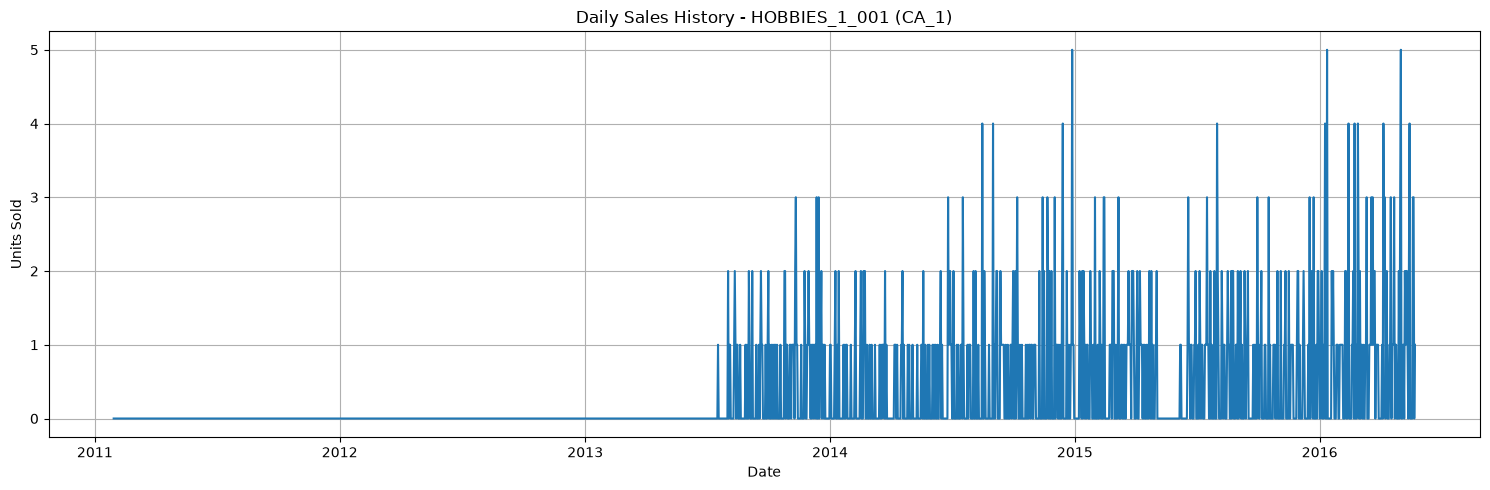

Total units sold: 633
Average daily demand: 0.33
Days with zero sales: 1505


In [16]:
import matplotlib.pyplot as plt

sample_series = sales.iloc[0]

sales_columns = [f"d_{i}" for i in range(1, 1942)]
sample_sales = sample_series[sales_columns].astype("int32").values

historical_dates = calendar.iloc[:1941]["date"]

plt.figure(figsize=(15, 5))
plt.plot(historical_dates, sample_sales)

plt.title(
    f"Daily Sales History - {sample_series['item_id']} "
    f"({sample_series['store_id']})"
)
plt.xlabel("Date")
plt.ylabel("Units Sold")
plt.grid(True)
plt.tight_layout()
plt.show()

print("Total units sold:", sample_sales.sum())
print("Average daily demand:", round(sample_sales.mean(), 2))
print("Days with zero sales:", (sample_sales == 0).sum())

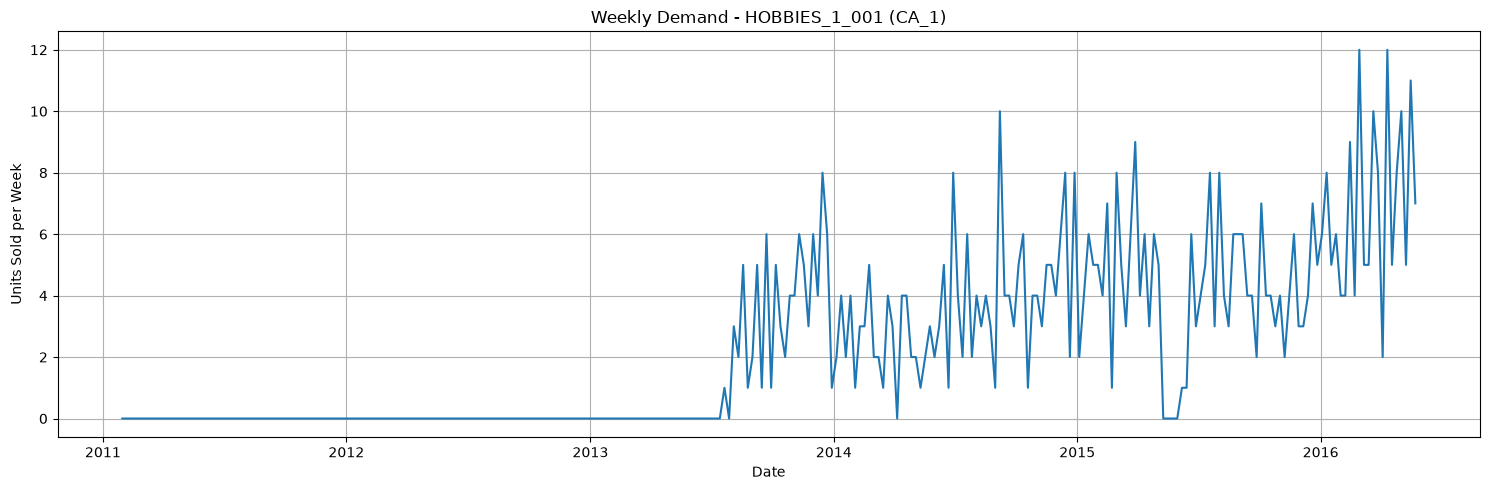

Average weekly demand: 2.28
Maximum weekly demand: 12
Weeks with zero sales: 135


In [17]:
sample_df = pd.DataFrame({
    "date": historical_dates.values,
    "sales": sample_sales
})

weekly_sales = (
    sample_df
    .set_index("date")["sales"]
    .resample("W")
    .sum()
)

plt.figure(figsize=(15, 5))
plt.plot(weekly_sales.index, weekly_sales.values)

plt.title("Weekly Demand - HOBBIES_1_001 (CA_1)")
plt.xlabel("Date")
plt.ylabel("Units Sold per Week")
plt.grid(True)
plt.tight_layout()
plt.show()

print("Average weekly demand:", round(weekly_sales.mean(), 2))
print("Maximum weekly demand:", weekly_sales.max())
print("Weeks with zero sales:", (weekly_sales == 0).sum())

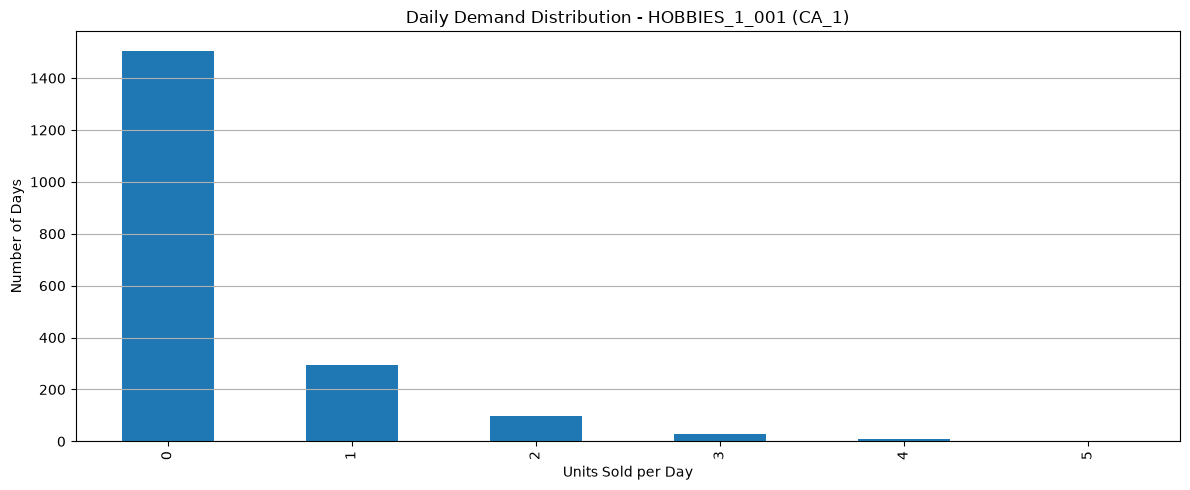

Demand distribution:
sales
0    1505
1     296
2      99
3      28
4      10
5       3
Name: count, dtype: int64


In [18]:
demand_distribution = (
    sample_df["sales"]
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(12, 5))
demand_distribution.plot(kind="bar")

plt.title("Daily Demand Distribution - HOBBIES_1_001 (CA_1)")
plt.xlabel("Units Sold per Day")
plt.ylabel("Number of Days")
plt.grid(axis="y")
plt.tight_layout()
plt.show()

print("Demand distribution:")
print(demand_distribution)

In [19]:
sample_item = sample_series["item_id"]
sample_store = sample_series["store_id"]

sample_prices = prices[
    (prices["item_id"] == sample_item) &
    (prices["store_id"] == sample_store)
].copy()

sample_prices = sample_prices.merge(
    calendar[["wm_yr_wk", "date"]].drop_duplicates("wm_yr_wk"),
    on="wm_yr_wk",
    how="left"
)

print("Product:", sample_item)
print("Store:", sample_store)
print("Price records:", len(sample_prices))
print("Minimum price:", sample_prices["sell_price"].min())
print("Maximum price:", sample_prices["sell_price"].max())

display(sample_prices.head())

Product: HOBBIES_1_001
Store: CA_1
Price records: 154
Minimum price: 8.26
Maximum price: 9.58


,store_id,item_id,wm_yr_wk,sell_price,date
0,CA_1,HOBBIES_1_001,11325,9.58,2013-07-13
1,CA_1,HOBBIES_1_001,11326,9.58,2013-07-20
2,CA_1,HOBBIES_1_001,11327,8.26,2013-07-27
3,CA_1,HOBBIES_1_001,11328,8.26,2013-08-03
4,CA_1,HOBBIES_1_001,11329,8.26,2013-08-10


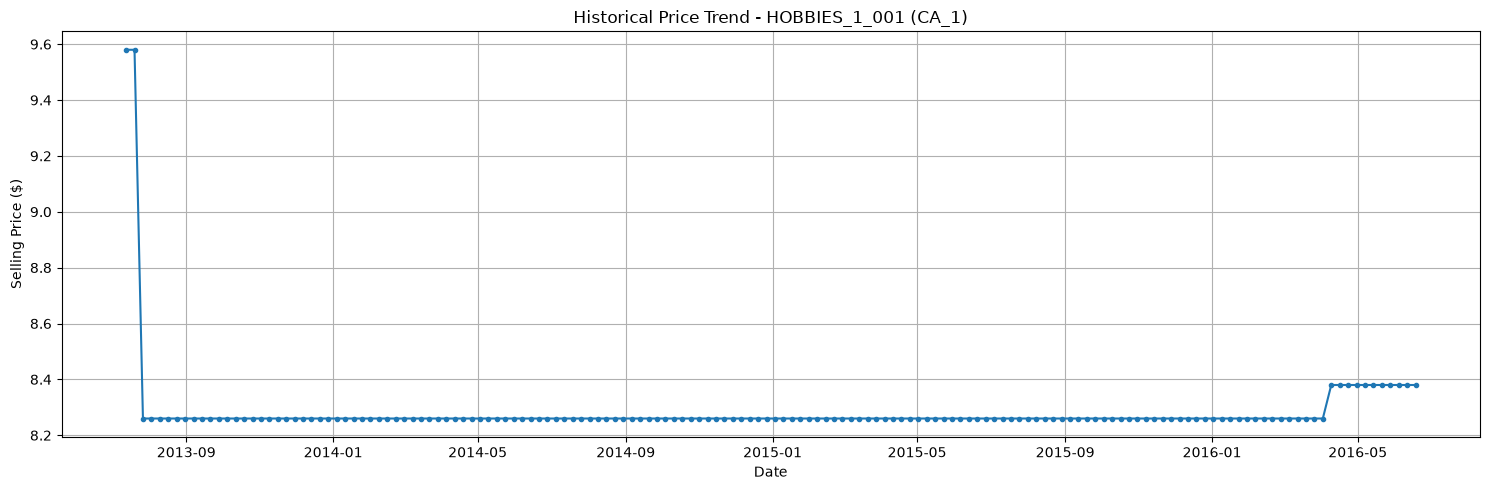

Average selling price: 8.29
Number of distinct prices: 3


In [20]:
plt.figure(figsize=(15, 5))

plt.plot(
    sample_prices["date"],
    sample_prices["sell_price"],
    marker="o",
    markersize=3
)

plt.title(f"Historical Price Trend - {sample_item} ({sample_store})")
plt.xlabel("Date")
plt.ylabel("Selling Price ($)")
plt.grid(True)
plt.tight_layout()
plt.show()

print("Average selling price:", round(sample_prices["sell_price"].mean(), 2))
print("Number of distinct prices:", sample_prices["sell_price"].nunique())


In [21]:
import importlib.util

libraries = [
    "sklearn",
    "lightgbm",
    "prophet",
    "statsmodels",
    "xgboost",
    "plotly",
    "dash",
    "ortools"
]

for library in libraries:
    installed = importlib.util.find_spec(library) is not None
    print(f"{library}: {'Installed' if installed else 'Not installed'}")

sklearn: Installed
lightgbm: Installed
prophet: Installed
statsmodels: Installed
xgboost: Installed
plotly: Installed
dash: Installed
ortools: Installed


In [22]:
%pip install prophet plotly dash ortools

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [23]:
import prophet
import plotly
import dash
import ortools

print("Prophet:", prophet.__version__)
print("Plotly:", plotly.__version__)
print("Dash:", dash.__version__)
print("OR-Tools: Installed successfully!")

Prophet: 1.5.0
Plotly: 7.1.0
Dash: 4.5.0
OR-Tools: Installed successfully!


In [24]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().parent
project_dir = PROJECT_ROOT / "DS-02_Demand_Forecasting_and_Inventory_Optimization"
raw_dir = project_dir / "data" / "raw"
processed_dir = project_dir / "data" / "processed"
models_dir = project_dir / "models"
outputs_dir = project_dir / "outputs"

calendar = pd.read_csv(raw_dir / "calendar.csv")
calendar["date"] = pd.to_datetime(calendar["date"])

for col in ["event_name_1", "event_type_1", "event_name_2", "event_type_2"]:
    calendar[col] = calendar[col].fillna("No Event")

calendar["day_of_week"] = calendar["date"].dt.dayofweek
calendar["is_weekend"] = (calendar["day_of_week"] >= 5).astype("int8")

sales = pd.read_csv(
    raw_dir / "sales_train_evaluation.csv",
    dtype={
        "item_id": "category",
        "dept_id": "category",
        "cat_id": "category",
        "store_id": "category",
        "state_id": "category",
        **{f"d_{i}": "int16" for i in range(1, 1942)}
    }
)

prices = pd.read_csv(
    raw_dir / "sell_prices.csv",
    dtype={"store_id": "category", "item_id": "category"}
)

print("Datasets restored successfully!")
print("Sales:", sales.shape)
print("Calendar:", calendar.shape)
print("Prices:", prices.shape)

Datasets restored successfully!
Sales: (30490, 1947)
Calendar: (1969, 16)
Prices: (6841121, 4)


In [25]:
# Select 20 products per category in every store
sampled_sales = (
    sales.groupby(
        ["store_id", "cat_id"],
        observed=True,
        group_keys=False
    )
    .sample(n=20, random_state=42)
    .reset_index(drop=True)
)

print("Selected time series:", len(sampled_sales))

print("\nStore coverage:")
print(sampled_sales["store_id"].value_counts().sort_index())

print("\nCategory coverage:")
print(sampled_sales["cat_id"].value_counts())

print("\nStore-category coverage:")
display(
    sampled_sales.groupby(
        ["store_id", "cat_id"],
        observed=True
    ).size().unstack()
)

Selected time series: 600

Store coverage:
store_id
CA_1    60
CA_2    60
CA_3    60
CA_4    60
TX_1    60
TX_2    60
TX_3    60
WI_1    60
WI_2    60
WI_3    60
Name: count, dtype: int64

Category coverage:
cat_id
HOBBIES      200
HOUSEHOLD    200
FOODS        200
Name: count, dtype: int64

Store-category coverage:


cat_id,HOBBIES,HOUSEHOLD,FOODS
store_id,,,
CA_1,20,20,20
CA_2,20,20,20
CA_3,20,20,20
CA_4,20,20,20
TX_1,20,20,20
TX_2,20,20,20
TX_3,20,20,20
WI_1,20,20,20
WI_2,20,20,20


In [26]:
sales_columns = [f"d_{i}" for i in range(1, 1942)]

daily_sales = sampled_sales.melt(
    id_vars=[
        "id", "item_id", "dept_id",
        "cat_id", "store_id", "state_id"
    ],
    value_vars=sales_columns,
    var_name="d",
    value_name="sales"
)

daily_sales = daily_sales.merge(
    calendar[["d", "date", "wm_yr_wk"]],
    on="d",
    how="left"
)

daily_sales["sales"] = daily_sales["sales"].astype("int16")

daily_sales = daily_sales.sort_values(
    ["id", "date"]
).reset_index(drop=True)

print("Daily sales dataset created!")
print("Shape:", daily_sales.shape)
print("Unique time series:", daily_sales["id"].nunique())
print("Date range:", daily_sales["date"].min(), "to", daily_sales["date"].max())
print("Memory usage:", round(
    daily_sales.memory_usage(deep=True).sum() / (1024**2), 2
), "MB")

display(daily_sales.head())

Daily sales dataset created!
Shape: (1164600, 10)
Unique time series: 600
Date range: 2011-01-29 00:00:00 to 2016-05-22 00:00:00
Memory usage: 191.78 MB


,id,item_id,dept_id,cat_id,store_id,state_id,d,sales,date,wm_yr_wk
0,FOODS_1_003_CA_3_evaluation,FOODS_1_003,FOODS_1,FOODS,CA_3,CA,d_1,1,2011-01-29,11101
1,FOODS_1_003_CA_3_evaluation,FOODS_1_003,FOODS_1,FOODS,CA_3,CA,d_2,1,2011-01-30,11101
2,FOODS_1_003_CA_3_evaluation,FOODS_1_003,FOODS_1,FOODS,CA_3,CA,d_3,1,2011-01-31,11101
3,FOODS_1_003_CA_3_evaluation,FOODS_1_003,FOODS_1,FOODS,CA_3,CA,d_4,3,2011-02-01,11101
4,FOODS_1_003_CA_3_evaluation,FOODS_1_003,FOODS_1,FOODS,CA_3,CA,d_5,0,2011-02-02,11101


In [27]:
# Identify the selected product-store combinations
selected_pairs = sampled_sales[["store_id", "item_id"]].drop_duplicates()

# Keep prices only for the selected combinations
selected_prices = prices.merge(
    selected_pairs,
    on=["store_id", "item_id"],
    how="inner"
)

# Merge prices into daily sales
daily_sales = daily_sales.merge(
    selected_prices,
    on=["store_id", "item_id", "wm_yr_wk"],
    how="left",
    validate="many_to_one"
)

print("Price data merged!")
print("Shape:", daily_sales.shape)
print("Missing prices:", daily_sales["sell_price"].isna().sum())
print("Unique time series:", daily_sales["id"].nunique())

display(daily_sales.head())

Price data merged!
Shape: (1164600, 11)
Missing prices: 244321
Unique time series: 600


,id,item_id,dept_id,cat_id,store_id,state_id,d,sales,date,wm_yr_wk,sell_price
0,FOODS_1_003_CA_3_evaluation,FOODS_1_003,FOODS_1,FOODS,CA_3,CA,d_1,1,2011-01-29,11101,2.88
1,FOODS_1_003_CA_3_evaluation,FOODS_1_003,FOODS_1,FOODS,CA_3,CA,d_2,1,2011-01-30,11101,2.88
2,FOODS_1_003_CA_3_evaluation,FOODS_1_003,FOODS_1,FOODS,CA_3,CA,d_3,1,2011-01-31,11101,2.88
3,FOODS_1_003_CA_3_evaluation,FOODS_1_003,FOODS_1,FOODS,CA_3,CA,d_4,3,2011-02-01,11101,2.88
4,FOODS_1_003_CA_3_evaluation,FOODS_1_003,FOODS_1,FOODS,CA_3,CA,d_5,0,2011-02-02,11101,2.88


In [28]:
# Select useful calendar features
calendar_features = calendar[
    [
        "d",
        "event_name_1",
        "event_type_1",
        "event_name_2",
        "event_type_2",
        "snap_CA",
        "snap_TX",
        "snap_WI"
    ]
].copy()

# Merge calendar features
daily_sales = daily_sales.merge(
    calendar_features,
    on="d",
    how="left",
    validate="many_to_one"
)

# Map each series to its state's SNAP indicator
daily_sales["snap"] = 0

daily_sales.loc[
    daily_sales["state_id"] == "CA", "snap"
] = daily_sales.loc[
    daily_sales["state_id"] == "CA", "snap_CA"
]

daily_sales.loc[
    daily_sales["state_id"] == "TX", "snap"
] = daily_sales.loc[
    daily_sales["state_id"] == "TX", "snap_TX"
]

daily_sales.loc[
    daily_sales["state_id"] == "WI", "snap"
] = daily_sales.loc[
    daily_sales["state_id"] == "WI", "snap_WI"
]

print("Calendar features merged!")
print("Shape:", daily_sales.shape)
print("Missing event values:", daily_sales["event_name_1"].isna().sum())
print("SNAP days:", daily_sales["snap"].sum())

display(
    daily_sales[
        ["date", "state_id", "event_name_1", "event_type_1", "snap"]
    ].head(10)
)

Calendar features merged!
Shape: (1164600, 19)
Missing event values: 0
SNAP days: 384000


,date,state_id,event_name_1,event_type_1,snap
0,2011-01-29,CA,No Event,No Event,0
1,2011-01-30,CA,No Event,No Event,0
2,2011-01-31,CA,No Event,No Event,0
3,2011-02-01,CA,No Event,No Event,1
4,2011-02-02,CA,No Event,No Event,1
5,2011-02-03,CA,No Event,No Event,1
6,2011-02-04,CA,No Event,No Event,1
7,2011-02-05,CA,No Event,No Event,1
8,2011-02-06,CA,SuperBowl,Sporting,1
9,2011-02-07,CA,No Event,No Event,1


In [29]:
# Investigate missing selling prices
missing_price = daily_sales[daily_sales["sell_price"].isna()]

print("Total missing price records:", len(missing_price))
print("Percentage missing:", round(
    len(missing_price) / len(daily_sales) * 100, 2
), "%")

print("\nMissing prices by category:")
display(
    missing_price["cat_id"].value_counts()
)

print("\nMissing prices by store:")
display(
    missing_price["store_id"].value_counts()
)

print("\nSales on dates with missing prices:")
display(
    missing_price.groupby("sales")["id"].count()
    .rename("record_count")
    .to_frame()
)

print("\nMissing price examples:")
display(
    missing_price[
        ["id", "date", "sales", "sell_price"]
    ].head(10)
)

Total missing price records: 244321
Percentage missing: 20.98 %

Missing prices by category:


cat_id
FOODS        85645
HOBBIES      81746
HOUSEHOLD    76930
Name: count, dtype: int64


Missing prices by store:


store_id
CA_2    30534
CA_4    28665
WI_3    28350
WI_2    26201
TX_2    24458
TX_3    23317
CA_1    23205
CA_3    22638
WI_1    19537
TX_1    17416
Name: count, dtype: int64


Sales on dates with missing prices:


,record_count
sales,
0,244321



Missing price examples:


,id,date,sales,sell_price
3882,FOODS_1_012_TX_2_evaluation,2011-01-29,0,NaN
3883,FOODS_1_012_TX_2_evaluation,2011-01-30,0,NaN
3884,FOODS_1_012_TX_2_evaluation,2011-01-31,0,NaN
3885,FOODS_1_012_TX_2_evaluation,2011-02-01,0,NaN
3886,FOODS_1_012_TX_2_evaluation,2011-02-02,0,NaN
3887,FOODS_1_012_TX_2_evaluation,2011-02-03,0,NaN
3888,FOODS_1_012_TX_2_evaluation,2011-02-04,0,NaN
3889,FOODS_1_012_TX_2_evaluation,2011-02-05,0,NaN
3890,FOODS_1_012_TX_2_evaluation,2011-02-06,0,NaN
3891,FOODS_1_012_TX_2_evaluation,2011-02-07,0,NaN


In [30]:
# Check whether missing prices occur before each product's first listed price

daily_sales["first_price_date"] = (
    daily_sales.groupby("id")["date"]
    .transform(
        lambda x: x.where(
            daily_sales.loc[x.index, "sell_price"].notna()
        ).min()
    )
)

missing_price = daily_sales[daily_sales["sell_price"].isna()].copy()

missing_price["before_first_price"] = (
    missing_price["date"] < missing_price["first_price_date"]
)

print("Missing-price records before first listed price:",
      missing_price["before_first_price"].sum())

print("Missing-price records after first listed price:",
      (~missing_price["before_first_price"]).sum())

print("\nPercentage before first listed price:",
      round(missing_price["before_first_price"].mean() * 100, 2), "%")

Missing-price records before first listed price: 244321
Missing-price records after first listed price: 0

Percentage before first listed price: 100.0 %


In [31]:
# Create product availability indicator

daily_sales["is_available"] = (
    daily_sales["sell_price"].notna().astype("int8")
)

print("Availability feature created!")

print("\nAvailability distribution:")
display(
    daily_sales["is_available"].value_counts()
    .rename(index={0: "Not Available", 1: "Available"})
)

print("\nAvailability by category:")
display(
    daily_sales.groupby("cat_id", observed=True)["is_available"]
    .mean()
    .mul(100)
    .round(2)
    .rename("Availability_Percentage")
    .to_frame()
)

Availability feature created!

Availability distribution:


is_available
Available        920279
Not Available    244321
Name: count, dtype: int64


Availability by category:


,Availability_Percentage
cat_id,
HOBBIES,78.94
HOUSEHOLD,80.18
FOODS,77.94


In [32]:
# Create lag features for historical demand

daily_sales = daily_sales.sort_values(
    ["id", "date"]
).reset_index(drop=True)

for lag in [7, 14, 28]:
    daily_sales[f"lag_{lag}"] = (
        daily_sales.groupby("id", observed=True)["sales"]
        .shift(lag)
    )

print("Lag features created!")

display(
    daily_sales[
        ["id", "date", "sales", "lag_7", "lag_14", "lag_28"]
    ].head(35)
)

Lag features created!


,id,date,sales,lag_7,lag_14,lag_28
0,FOODS_1_003_CA_3_evaluation,2011-01-29,1,NaN,NaN,NaN
1,FOODS_1_003_CA_3_evaluation,2011-01-30,1,NaN,NaN,NaN
2,FOODS_1_003_CA_3_evaluation,2011-01-31,1,NaN,NaN,NaN
3,FOODS_1_003_CA_3_evaluation,2011-02-01,3,NaN,NaN,NaN
4,FOODS_1_003_CA_3_evaluation,2011-02-02,0,NaN,NaN,NaN
5,FOODS_1_003_CA_3_evaluation,2011-02-03,2,NaN,NaN,NaN
6,FOODS_1_003_CA_3_evaluation,2011-02-04,1,NaN,NaN,NaN
7,FOODS_1_003_CA_3_evaluation,2011-02-05,1,1.0,NaN,NaN
8,FOODS_1_003_CA_3_evaluation,2011-02-06,1,1.0,NaN,NaN
9,FOODS_1_003_CA_3_evaluation,2011-02-07,1,1.0,NaN,NaN


In [33]:
# Create rolling demand features (leakage-safe)

sales_group = daily_sales.groupby("id", observed=True)["sales"]

for window in [7, 28, 56]:
    daily_sales[f"rolling_mean_{window}"] = (
        sales_group.transform(
            lambda x: x.shift(1).rolling(window).mean()
        )
    )

daily_sales["rolling_std_28"] = (
    sales_group.transform(
        lambda x: x.shift(1).rolling(28).std()
    )
)

print("Rolling features created!")

display(
    daily_sales[
        [
            "id", "date", "sales",
            "rolling_mean_7",
            "rolling_mean_28",
            "rolling_mean_56",
            "rolling_std_28"
        ]
    ].iloc[25:40]
)

Rolling features created!


,id,date,sales,rolling_mean_7,rolling_mean_28,rolling_mean_56,rolling_std_28
25,FOODS_1_003_CA_3_evaluation,2011-02-23,2,0.714286,NaN,NaN,NaN
26,FOODS_1_003_CA_3_evaluation,2011-02-24,2,1.000000,NaN,NaN,NaN
27,FOODS_1_003_CA_3_evaluation,2011-02-25,0,1.285714,NaN,NaN,NaN
28,FOODS_1_003_CA_3_evaluation,2011-02-26,0,1.285714,1.357143,NaN,1.366647
29,FOODS_1_003_CA_3_evaluation,2011-02-27,3,1.000000,1.321429,NaN,1.389206
30,FOODS_1_003_CA_3_evaluation,2011-02-28,0,1.142857,1.392857,NaN,1.423071
31,FOODS_1_003_CA_3_evaluation,2011-03-01,2,1.142857,1.357143,NaN,1.445665
32,FOODS_1_003_CA_3_evaluation,2011-03-02,1,1.285714,1.321429,NaN,1.415616
33,FOODS_1_003_CA_3_evaluation,2011-03-03,0,1.142857,1.357143,NaN,1.393484
34,FOODS_1_003_CA_3_evaluation,2011-03-04,0,0.857143,1.285714,NaN,1.410467


In [34]:
# Create calendar-based forecasting features

daily_sales["day_of_week"] = daily_sales["date"].dt.dayofweek
daily_sales["day_of_month"] = daily_sales["date"].dt.day
daily_sales["month"] = daily_sales["date"].dt.month
daily_sales["year"] = daily_sales["date"].dt.year
daily_sales["week_of_year"] = (
    daily_sales["date"].dt.isocalendar().week.astype("int16")
)

daily_sales["is_weekend"] = (
    daily_sales["day_of_week"] >= 5
).astype("int8")

daily_sales["has_event"] = (
    (daily_sales["event_name_1"] != "No Event") |
    (daily_sales["event_name_2"] != "No Event")
).astype("int8")

print("Calendar features created!")

display(
    daily_sales[
        [
            "date",
            "day_of_week",
            "day_of_month",
            "month",
            "year",
            "week_of_year",
            "is_weekend",
            "has_event",
            "snap"
        ]
    ].head(15)
)

Calendar features created!


,date,day_of_week,day_of_month,month,year,week_of_year,is_weekend,has_event,snap
0,2011-01-29,5,29,1,2011,4,1,0,0
1,2011-01-30,6,30,1,2011,4,1,0,0
2,2011-01-31,0,31,1,2011,5,0,0,0
3,2011-02-01,1,1,2,2011,5,0,0,1
4,2011-02-02,2,2,2,2011,5,0,0,1
5,2011-02-03,3,3,2,2011,5,0,0,1
6,2011-02-04,4,4,2,2011,5,0,0,1
7,2011-02-05,5,5,2,2011,5,1,0,1
8,2011-02-06,6,6,2,2011,5,1,1,1
9,2011-02-07,0,7,2,2011,6,0,0,1


In [35]:
# Create price-related features

daily_sales = daily_sales.sort_values(
    ["id", "date"]
).reset_index(drop=True)

daily_sales["previous_price"] = (
    daily_sales.groupby("id", observed=True)["sell_price"]
    .shift(1)
)

daily_sales["price_change"] = (
    daily_sales["sell_price"] - daily_sales["previous_price"]
)

daily_sales["price_change_pct"] = (
    daily_sales["price_change"] /
    daily_sales["previous_price"]
)

daily_sales["price_change_pct"] = (
    daily_sales["price_change_pct"].replace(
        [float("inf"), float("-inf")], float("nan")
    )
)

print("Price features created!")

display(
    daily_sales[
        [
            "id", "date", "sell_price",
            "previous_price",
            "price_change",
            "price_change_pct"
        ]
    ].iloc[145:165]
)

Price features created!


,id,date,sell_price,previous_price,price_change,price_change_pct
145,FOODS_1_003_CA_3_evaluation,2011-06-23,2.88,2.88,0.0,0.0
146,FOODS_1_003_CA_3_evaluation,2011-06-24,2.88,2.88,0.0,0.0
147,FOODS_1_003_CA_3_evaluation,2011-06-25,2.88,2.88,0.0,0.0
148,FOODS_1_003_CA_3_evaluation,2011-06-26,2.88,2.88,0.0,0.0
149,FOODS_1_003_CA_3_evaluation,2011-06-27,2.88,2.88,0.0,0.0
150,FOODS_1_003_CA_3_evaluation,2011-06-28,2.88,2.88,0.0,0.0
151,FOODS_1_003_CA_3_evaluation,2011-06-29,2.88,2.88,0.0,0.0
152,FOODS_1_003_CA_3_evaluation,2011-06-30,2.88,2.88,0.0,0.0
153,FOODS_1_003_CA_3_evaluation,2011-07-01,2.88,2.88,0.0,0.0
154,FOODS_1_003_CA_3_evaluation,2011-07-02,2.88,2.88,0.0,0.0


In [36]:
# Analyze price changes across all sampled products

print("Price change statistics:")
display(
    daily_sales["price_change"]
    .describe()
    .to_frame()
)

print("\nNumber of price changes:")
print(
    (daily_sales["price_change"] != 0).sum()
)

print("\nNumber of unchanged price records:")
print(
    (daily_sales["price_change"] == 0).sum()
)

print("\nLargest price increases:")
display(
    daily_sales.nlargest(
        5, "price_change"
    )[["id", "date", "sell_price", "previous_price", "price_change"]]
)

print("\nLargest price decreases:")
display(
    daily_sales.nsmallest(
        5, "price_change"
    )[["id", "date", "sell_price", "previous_price", "price_change"]]
)

Price change statistics:


,price_change
count,919679.000000
mean,0.000022
std,0.068967
min,-37.390000
25%,0.000000
50%,0.000000
75%,0.000000
max,37.390000



Number of price changes:
246265

Number of unchanged price records:
918335

Largest price increases:


,id,date,sell_price,previous_price,price_change
1023439,HOUSEHOLD_2_178_TX_1_evaluation,2012-07-14,44.36,6.97,37.39
808807,HOUSEHOLD_1_056_TX_2_evaluation,2014-10-11,11.97,3.49,8.48
929338,HOUSEHOLD_1_469_CA_2_evaluation,2015-04-18,17.97,9.98,7.99
472286,HOBBIES_1_144_CA_3_evaluation,2012-10-13,10.98,5.48,5.50
1032745,HOUSEHOLD_2_211_WI_2_evaluation,2011-06-11,20.00,15.00,5.00



Largest price decreases:


,id,date,sell_price,previous_price,price_change
1023460,HOUSEHOLD_2_178_TX_1_evaluation,2012-08-04,6.97,44.36,-37.39
808800,HOUSEHOLD_1_056_TX_2_evaluation,2014-10-04,3.49,11.97,-8.48
929331,HOUSEHOLD_1_469_CA_2_evaluation,2015-04-11,9.98,17.97,-7.99
472237,HOBBIES_1_144_CA_3_evaluation,2012-08-25,5.48,10.98,-5.50
1032703,HOUSEHOLD_2_211_WI_2_evaluation,2011-04-30,15.00,20.00,-5.00


In [37]:
# Final feature engineering audit

print("Dataset shape:", daily_sales.shape)

print("\nAvailable columns:")
for column in daily_sales.columns:
    print("-", column)

print("\nMissing values in engineered features:")
engineered_features = [
    "lag_7", "lag_14", "lag_28",
    "rolling_mean_7", "rolling_mean_28",
    "rolling_mean_56", "rolling_std_28",
    "day_of_week", "month", "year",
    "is_weekend", "has_event", "snap",
    "price_change", "price_change_pct",
    "is_available"
]

display(
    daily_sales[engineered_features]
    .isna()
    .sum()
    .to_frame("Missing Values")
)

print(
    "\nMemory usage:",
    round(
        daily_sales.memory_usage(deep=True).sum() / (1024**2),
        2
    ),
    "MB"
)

Dataset shape: (1164600, 38)

Available columns:
- id
- item_id
- dept_id
- cat_id
- store_id
- state_id
- d
- sales
- date
- wm_yr_wk
- sell_price
- event_name_1
- event_type_1
- event_name_2
- event_type_2
- snap_CA
- snap_TX
- snap_WI
- snap
- first_price_date
- is_available
- lag_7
- lag_14
- lag_28
- rolling_mean_7
- rolling_mean_28
- rolling_mean_56
- rolling_std_28
- day_of_week
- day_of_month
- month
- year
- week_of_year
- is_weekend
- has_event
- previous_price
- price_change
- price_change_pct

Missing values in engineered features:


,Missing Values
lag_7,4200
lag_14,8400
lag_28,16800
rolling_mean_7,4200
rolling_mean_28,16800
rolling_mean_56,33600
rolling_std_28,16800
day_of_week,0
month,0
year,0



Memory usage: 646.38 MB


In [38]:
# Prepare the LightGBM modelling dataset

feature_columns = [
    "item_id",
    "dept_id",
    "cat_id",
    "store_id",
    "state_id",
    "sell_price",
    "price_change",
    "price_change_pct",
    "lag_7",
    "lag_14",
    "lag_28",
    "rolling_mean_7",
    "rolling_mean_28",
    "rolling_mean_56",
    "rolling_std_28",
    "day_of_week",
    "day_of_month",
    "month",
    "year",
    "week_of_year",
    "is_weekend",
    "has_event",
    "event_name_1",
    "event_type_1",
    "event_name_2",
    "event_type_2",
    "snap"
]

model_data = daily_sales.loc[
    daily_sales["is_available"] == 1,
    ["id", "date", "sales"] + feature_columns
].copy()

print("Modelling dataset prepared!")
print("Shape:", model_data.shape)
print("Unique series:", model_data["id"].nunique())
print("Date range:", model_data["date"].min(), "to", model_data["date"].max())

print("\nRemaining missing values:")
display(
    model_data[feature_columns]
    .isna()
    .sum()
    .to_frame("Missing Values")
    .query("`Missing Values` > 0")
)

print("\nMemory usage:",
      round(model_data.memory_usage(deep=True).sum() / (1024**2), 2),
      "MB")

Modelling dataset prepared!
Shape: (920279, 30)
Unique series: 600
Date range: 2011-01-29 00:00:00 to 2016-05-22 00:00:00

Remaining missing values:


,Missing Values
price_change,600
price_change_pct,600
lag_7,1407
lag_14,2947
lag_28,6223
rolling_mean_7,1407
rolling_mean_28,6223
rolling_mean_56,13293
rolling_std_28,6223



Memory usage: 420.07 MB


In [39]:
# Recalculate demand features using available product-days only

daily_sales = daily_sales.sort_values(
    ["id", "date"]
).reset_index(drop=True)

# Exclude pre-launch sales from historical demand calculations
available_sales = daily_sales["sales"].where(
    daily_sales["is_available"] == 1
)

sales_group = available_sales.groupby(
    daily_sales["id"], observed=True
)

# Rebuild lag features
for lag in [7, 14, 28]:
    daily_sales[f"lag_{lag}"] = sales_group.transform(
        lambda x: x.shift(lag)
    )

# Rebuild rolling features
for window in [7, 28, 56]:
    daily_sales[f"rolling_mean_{window}"] = (
        sales_group.transform(
            lambda x: x.shift(1).rolling(window).mean()
        )
    )

daily_sales["rolling_std_28"] = sales_group.transform(
    lambda x: x.shift(1).rolling(28).std()
)

# Refresh modelling dataset
model_data = daily_sales.loc[
    daily_sales["is_available"] == 1,
    ["id", "date", "sales"] + feature_columns
].copy()

print("Demand features recalculated!")
print("Modelling dataset shape:", model_data.shape)

print("\nMissing historical features:")
display(
    model_data[
        [
            "lag_7", "lag_14", "lag_28",
            "rolling_mean_7", "rolling_mean_28",
            "rolling_mean_56", "rolling_std_28"
        ]
    ].isna().sum().to_frame("Missing Values")
)

Demand features recalculated!
Modelling dataset shape: (920279, 30)

Missing historical features:


,Missing Values
lag_7,4200
lag_14,8400
lag_28,16800
rolling_mean_7,4200
rolling_mean_28,16800
rolling_mean_56,33600
rolling_std_28,16800


In [40]:
# Create chronological training and validation datasets

validation_start = (
    model_data["date"].max() - pd.Timedelta(days=27)
)

train_data = model_data[
    model_data["date"] < validation_start
].copy()

valid_data = model_data[
    model_data["date"] >= validation_start
].copy()

print("Training period:")
print(train_data["date"].min(), "to", train_data["date"].max())

print("\nValidation period:")
print(valid_data["date"].min(), "to", valid_data["date"].max())

print("\nTraining observations:", len(train_data))
print("Validation observations:", len(valid_data))

print("\nTraining series:", train_data["id"].nunique())
print("Validation series:", valid_data["id"].nunique())

print("\nValidation days:", valid_data["date"].nunique())

Training period:
2011-01-29 00:00:00 to 2016-04-24 00:00:00

Validation period:
2016-04-25 00:00:00 to 2016-05-22 00:00:00

Training observations: 903479
Validation observations: 16800

Training series: 600
Validation series: 600

Validation days: 28


In [41]:
# Naive forecasting baseline: previous day's demand

valid_data = valid_data.sort_values(
    ["id", "date"]
).copy()

# Get the previous day's actual sales for each product-store series
valid_data["naive_forecast"] = (
    daily_sales.groupby("id", observed=True)["sales"]
    .shift(1)
    .loc[valid_data.index]
)

print("Naive baseline created!")

print("\nValidation sample:")
display(
    valid_data[
        ["id", "date", "sales", "naive_forecast"]
    ].head(15)
)

print("\nMissing baseline predictions:",
      valid_data["naive_forecast"].isna().sum())

Naive baseline created!

Validation sample:


,id,date,sales,naive_forecast
1913,FOODS_1_003_CA_3_evaluation,2016-04-25,1,0.0
1914,FOODS_1_003_CA_3_evaluation,2016-04-26,1,1.0
1915,FOODS_1_003_CA_3_evaluation,2016-04-27,0,1.0
1916,FOODS_1_003_CA_3_evaluation,2016-04-28,1,0.0
1917,FOODS_1_003_CA_3_evaluation,2016-04-29,0,1.0
1918,FOODS_1_003_CA_3_evaluation,2016-04-30,0,0.0
1919,FOODS_1_003_CA_3_evaluation,2016-05-01,3,0.0
1920,FOODS_1_003_CA_3_evaluation,2016-05-02,0,3.0
1921,FOODS_1_003_CA_3_evaluation,2016-05-03,0,0.0
1922,FOODS_1_003_CA_3_evaluation,2016-05-04,1,0.0



Missing baseline predictions: 0


In [42]:
# Create a genuine 28-day naive forecast

last_training_sales = (
    train_data.sort_values(["id", "date"])
    .groupby("id", observed=True)
    .tail(1)[["id", "sales"]]
    .rename(columns={"sales": "last_observed_sales"})
)

valid_data = valid_data.drop(
    columns=["naive_forecast"],
    errors="ignore"
)

valid_data = valid_data.merge(
    last_training_sales,
    on="id",
    how="left",
    validate="many_to_one"
)

valid_data["naive_forecast"] = (
    valid_data["last_observed_sales"]
)

print("28-day naive forecast created!")

print("\nValidation sample:")
display(
    valid_data[
        ["id", "date", "sales", "last_observed_sales",
         "naive_forecast"]
    ].head(15)
)

print("\nMissing predictions:",
      valid_data["naive_forecast"].isna().sum())

print("\nForecast horizon:",
      valid_data["date"].nunique(), "days")

28-day naive forecast created!

Validation sample:


,id,date,sales,last_observed_sales,naive_forecast
0,FOODS_1_003_CA_3_evaluation,2016-04-25,1,0,0
1,FOODS_1_003_CA_3_evaluation,2016-04-26,1,0,0
2,FOODS_1_003_CA_3_evaluation,2016-04-27,0,0,0
3,FOODS_1_003_CA_3_evaluation,2016-04-28,1,0,0
4,FOODS_1_003_CA_3_evaluation,2016-04-29,0,0,0
5,FOODS_1_003_CA_3_evaluation,2016-04-30,0,0,0
6,FOODS_1_003_CA_3_evaluation,2016-05-01,3,0,0
7,FOODS_1_003_CA_3_evaluation,2016-05-02,0,0,0
8,FOODS_1_003_CA_3_evaluation,2016-05-03,0,0,0
9,FOODS_1_003_CA_3_evaluation,2016-05-04,1,0,0



Missing predictions: 0

Forecast horizon: 28 days


In [43]:
import numpy as np
import pandas as pd

# 1. Calculate overall WAPE
wape = (
    np.abs(valid_data["sales"] - valid_data["naive_forecast"]).sum()
    / valid_data["sales"].sum()
) * 100

# 2. Calculate RMSSE for each product-store series
rmsse_results = []

for series_id, train_group in train_data.groupby("id", observed=True):

    valid_group = valid_data[valid_data["id"] == series_id]

    train_values = train_group.sort_values("date")["sales"].to_numpy()
    actual_values = valid_group.sort_values("date")["sales"].to_numpy()
    forecast_values = valid_group.sort_values("date")["naive_forecast"].to_numpy()

    # Training-period scaling denominator
    denominator = np.mean(np.diff(train_values) ** 2)

    # Validation-period forecast error
    numerator = np.mean((actual_values - forecast_values) ** 2)

    if denominator > 0:
        rmsse = np.sqrt(numerator / denominator)
    else:
        rmsse = np.nan

    rmsse_results.append({
        "id": series_id,
        "RMSSE": rmsse
    })

rmsse_df = pd.DataFrame(rmsse_results)

mean_rmsse = rmsse_df["RMSSE"].mean()

# 3. Display results
print("NAIVE BASELINE — 28-DAY VALIDATION")
print("-" * 45)
print(f"WAPE: {wape:.2f}%")
print(f"Mean RMSSE: {mean_rmsse:.4f}")
print(f"Series evaluated: {rmsse_df['RMSSE'].notna().sum()}")
print(f"Series with undefined RMSSE: {rmsse_df['RMSSE'].isna().sum()}")

NAIVE BASELINE — 28-DAY VALIDATION
---------------------------------------------
WAPE: 101.11%
Mean RMSSE: 1.0495
Series evaluated: 600
Series with undefined RMSSE: 0


In [44]:
# Select a representative product-store series

series_summary = (
    model_data.groupby("id", observed=True)
    .agg(
        observations=("sales", "count"),
        total_sales=("sales", "sum"),
        average_sales=("sales", "mean")
    )
    .sort_values("total_sales", ascending=False)
)

display(series_summary.head(10))

,observations,total_sales,average_sales
id,,,
HOUSEHOLD_1_234_CA_3_evaluation,1941,22186,11.430191
HOUSEHOLD_1_409_CA_3_evaluation,1192,17856,14.979866
FOODS_1_082_WI_2_evaluation,1171,16659,14.226302
HOUSEHOLD_1_083_TX_2_evaluation,1927,16534,8.580176
FOODS_3_804_TX_1_evaluation,1941,15711,8.094281
FOODS_1_012_TX_2_evaluation,1850,15671,8.470811
FOODS_3_348_TX_2_evaluation,1941,14264,7.348789
HOUSEHOLD_1_083_WI_3_evaluation,1941,13990,7.207625
FOODS_1_046_CA_1_evaluation,1941,13839,7.129830


In [45]:
# Select one product-store series
prophet_series_id = "HOUSEHOLD_1_234_CA_3_evaluation"

prophet_data = model_data[
    model_data["id"] == prophet_series_id
][["date", "sales"]].copy()

# Prophet requires columns named ds and y
prophet_data = prophet_data.rename(
    columns={
        "date": "ds",
        "sales": "y"
    }
)

# Chronological split
prophet_train = prophet_data[
    prophet_data["ds"] < validation_start
].copy()

prophet_valid = prophet_data[
    prophet_data["ds"] >= validation_start
].copy()

print("Selected series:", prophet_series_id)
print("Training observations:", len(prophet_train))
print("Validation observations:", len(prophet_valid))
print("Training period:", prophet_train["ds"].min(), "to", prophet_train["ds"].max())
print("Validation period:", prophet_valid["ds"].min(), "to", prophet_valid["ds"].max())

display(prophet_train.tail())
display(prophet_valid.head())

Selected series: HOUSEHOLD_1_234_CA_3_evaluation
Training observations: 1913
Validation observations: 28
Training period: 2011-01-29 00:00:00 to 2016-04-24 00:00:00
Validation period: 2016-04-25 00:00:00 to 2016-05-22 00:00:00


,ds,y
854007,2016-04-20,0
854008,2016-04-21,12
854009,2016-04-22,12
854010,2016-04-23,12
854011,2016-04-24,8


,ds,y
854012,2016-04-25,4
854013,2016-04-26,7
854014,2016-04-27,10
854015,2016-04-28,7
854016,2016-04-29,14


In [46]:
from prophet import Prophet

prophet_model = Prophet(
    yearly_seasonality=True,
    weekly_seasonality=True,
    daily_seasonality=False,
    seasonality_mode="additive",
    interval_width=0.95
)

prophet_model.fit(prophet_train)

print("Prophet model training completed!")

07:54:53 - cmdstanpy - INFO - Chain [1] start processing
07:54:54 - cmdstanpy - INFO - Chain [1] done processing


Prophet model training completed!


In [47]:
# Generate future dates for the validation period
future = prophet_model.make_future_dataframe(
    periods=28,
    freq="D"
)

# Generate predictions
prophet_forecast = prophet_model.predict(future)

# Extract validation-period predictions
prophet_predictions = prophet_forecast[
    prophet_forecast["ds"].isin(prophet_valid["ds"])
][["ds", "yhat", "yhat_lower", "yhat_upper"]].copy()

# Display forecast
print("Prophet forecast generated!")
print("Forecast days:", len(prophet_predictions))

display(prophet_predictions.head(10))

Prophet forecast generated!
Forecast days: 28


,ds,yhat,yhat_lower,yhat_upper
1913,2016-04-25,4.555527,-7.349611,16.973175
1914,2016-04-26,3.330496,-8.625342,15.064502
1915,2016-04-27,4.322557,-7.046454,16.778403
1916,2016-04-28,3.837485,-8.128271,16.201829
1917,2016-04-29,4.942959,-7.046795,16.420176
1918,2016-04-30,7.866603,-4.353637,19.427341
1919,2016-05-01,7.274068,-3.906370,18.702171
1920,2016-05-02,5.017634,-6.033684,16.980533
1921,2016-05-03,3.809423,-7.572331,16.738638
1922,2016-05-04,4.804574,-8.199278,16.553578


In [48]:
# Merge actual demand with Prophet predictions
prophet_evaluation = prophet_valid.merge(
    prophet_predictions,
    on="ds",
    how="inner"
)

# Clip negative forecasts to zero
prophet_evaluation["yhat_clipped"] = (
    prophet_evaluation["yhat"].clip(lower=0)
)

# Calculate WAPE
prophet_wape = (
    np.abs(
        prophet_evaluation["y"] -
        prophet_evaluation["yhat_clipped"]
    ).sum()
    / prophet_evaluation["y"].sum()
) * 100

# Calculate RMSE
prophet_rmse = np.sqrt(
    np.mean(
        (prophet_evaluation["y"] -
         prophet_evaluation["yhat_clipped"]) ** 2
    )
)

print("PROPHET — 28-DAY VALIDATION")
print("-" * 40)
print(f"WAPE: {prophet_wape:.2f}%")
print(f"RMSE: {prophet_rmse:.4f}")

display(
    prophet_evaluation[
        ["ds", "y", "yhat", "yhat_clipped",
         "yhat_lower", "yhat_upper"]
    ].head(10)
)

PROPHET — 28-DAY VALIDATION
----------------------------------------
WAPE: 53.26%
RMSE: 4.6373


,ds,y,yhat,yhat_clipped,yhat_lower,yhat_upper
0,2016-04-25,4,4.555527,4.555527,-7.349611,16.973175
1,2016-04-26,7,3.330496,3.330496,-8.625342,15.064502
2,2016-04-27,10,4.322557,4.322557,-7.046454,16.778403
3,2016-04-28,7,3.837485,3.837485,-8.128271,16.201829
4,2016-04-29,14,4.942959,4.942959,-7.046795,16.420176
5,2016-04-30,6,7.866603,7.866603,-4.353637,19.427341
6,2016-05-01,10,7.274068,7.274068,-3.906370,18.702171
7,2016-05-02,12,5.017634,5.017634,-6.033684,16.980533
8,2016-05-03,6,3.809423,3.809423,-7.572331,16.738638
9,2016-05-04,7,4.804574,4.804574,-8.199278,16.553578


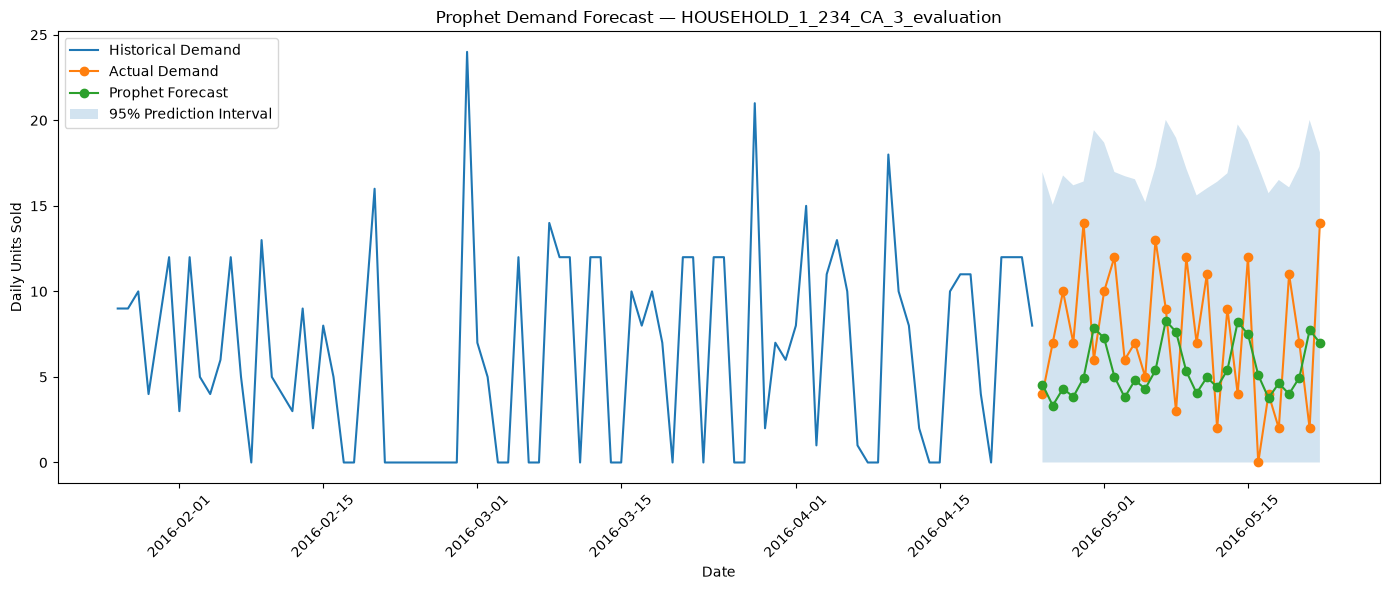

In [49]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.plot(
    prophet_train["ds"].tail(90),
    prophet_train["y"].tail(90),
    label="Historical Demand"
)

plt.plot(
    prophet_evaluation["ds"],
    prophet_evaluation["y"],
    label="Actual Demand",
    marker="o"
)

plt.plot(
    prophet_evaluation["ds"],
    prophet_evaluation["yhat_clipped"],
    label="Prophet Forecast",
    marker="o"
)

plt.fill_between(
    prophet_evaluation["ds"],
    prophet_evaluation["yhat_lower"].clip(lower=0),
    prophet_evaluation["yhat_upper"],
    alpha=0.2,
    label="95% Prediction Interval"
)

plt.title(f"Prophet Demand Forecast — {prophet_series_id}")
plt.xlabel("Date")
plt.ylabel("Daily Units Sold")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [50]:
import lightgbm as lgb

# Select the same product-store series
lgb_series = model_data[
    model_data["id"] == prophet_series_id
].copy()

# Chronological split
lgb_train = lgb_series[
    lgb_series["date"] < validation_start
].copy()

lgb_valid = lgb_series[
    lgb_series["date"] >= validation_start
].copy()

# Select features
lgb_features = [
    "sell_price",
    "price_change",
    "price_change_pct",
    "lag_7",
    "lag_14",
    "lag_28",
    "rolling_mean_7",
    "rolling_mean_28",
    "rolling_mean_56",
    "rolling_std_28",
    "day_of_week",
    "day_of_month",
    "month",
    "year",
    "week_of_year",
    "is_weekend",
    "has_event",
    "snap"
]

# Prepare X and y
X_train = lgb_train[lgb_features]
y_train = lgb_train["sales"]

X_valid = lgb_valid[lgb_features]
y_valid = lgb_valid["sales"]

print("LightGBM dataset prepared!")
print("Training shape:", X_train.shape)
print("Validation shape:", X_valid.shape)
print("Features:", len(lgb_features))
print("Missing training values:", X_train.isna().sum().sum())
print("Missing validation values:", X_valid.isna().sum().sum())

LightGBM dataset prepared!
Training shape: (1913, 18)
Validation shape: (28, 18)
Features: 18
Missing training values: 170
Missing validation values: 0


In [51]:
lgb_model = lgb.LGBMRegressor(
    objective="regression",
    n_estimators=500,
    learning_rate=0.03,
    num_leaves=15,
    max_depth=-1,
    min_child_samples=20,
    subsample=0.8,
    colsample_bytree=0.9,
    reg_alpha=0.1,
    reg_lambda=0.1,
    random_state=42,
    verbosity=-1
)

lgb_model.fit(X_train, y_train)

print("LightGBM model training completed!")
print("Trees trained:", lgb_model.n_estimators_)

LightGBM model training completed!
Trees trained: 500


In [52]:
# Store historical training demand
history = lgb_train.sort_values("date")["sales"].astype(float).tolist()

lgb_predictions = []

# Forecast one day at a time
for _, row in lgb_valid.sort_values("date").iterrows():

    features = row[lgb_features].copy()

    # Recalculate demand-based features using forecast history
    features["lag_7"] = history[-7]
    features["lag_14"] = history[-14]
    features["lag_28"] = history[-28]

    features["rolling_mean_7"] = np.mean(history[-7:])
    features["rolling_mean_28"] = np.mean(history[-28:])
    features["rolling_mean_56"] = np.mean(history[-56:])
    features["rolling_std_28"] = np.std(history[-28:], ddof=1)

    # Predict demand
    prediction = lgb_model.predict(
        pd.DataFrame([features], columns=lgb_features)
    )[0]

    # Demand cannot be negative
    prediction = max(0, prediction)

    lgb_predictions.append(prediction)

    # Append prediction for the next forecasting day
    history.append(prediction)

# Store results
lgb_evaluation = lgb_valid[["date", "sales"]].copy()
lgb_evaluation["lgb_forecast"] = lgb_predictions

print("LightGBM recursive forecasting completed!")
print("Forecast horizon:", len(lgb_predictions), "days")

display(lgb_evaluation.head(10))

LightGBM recursive forecasting completed!
Forecast horizon: 28 days


,date,sales,lgb_forecast
854012,2016-04-25,4,7.771631
854013,2016-04-26,7,6.432401
854014,2016-04-27,10,7.195540
854015,2016-04-28,7,7.163780
854016,2016-04-29,14,8.102730
854017,2016-04-30,6,7.397015
854018,2016-05-01,10,12.625316
854019,2016-05-02,12,7.504450
854020,2016-05-03,6,6.741809
854021,2016-05-04,7,6.039912


In [53]:
# Calculate naive forecast for this selected series
naive_forecast = np.repeat(
    lgb_train.sort_values("date")["sales"].iloc[-1],
    len(lgb_evaluation)
)

actual = lgb_evaluation["sales"].to_numpy()
prophet_pred = prophet_evaluation["yhat_clipped"].to_numpy()
lightgbm_pred = lgb_evaluation["lgb_forecast"].to_numpy()

# Metric calculation
def calculate_metrics(actual, forecast):
    wape = (
        np.abs(actual - forecast).sum() / actual.sum()
    ) * 100

    rmse = np.sqrt(np.mean((actual - forecast) ** 2))

    return wape, rmse

# Evaluate all models
results = []

for model_name, predictions in [
    ("Naive", naive_forecast),
    ("Prophet", prophet_pred),
    ("LightGBM", lightgbm_pred)
]:
    model_wape, model_rmse = calculate_metrics(
        actual, predictions
    )

    results.append({
        "Model": model_name,
        "WAPE (%)": round(model_wape, 2),
        "RMSE": round(model_rmse, 4)
    })

comparison_df = pd.DataFrame(results)

print("MODEL COMPARISON — SELECTED SERIES")
display(comparison_df)

MODEL COMPARISON — SELECTED SERIES


,Model,WAPE (%),RMSE
0,Naive,45.71,3.9641
1,Prophet,53.26,4.6373
2,LightGBM,46.23,4.1848


,Feature,Importance
6,rolling_mean_7,914
8,rolling_mean_56,871
9,rolling_std_28,847
7,rolling_mean_28,742
11,day_of_month,637
4,lag_14,618
5,lag_28,555
3,lag_7,553
14,week_of_year,514
10,day_of_week,395


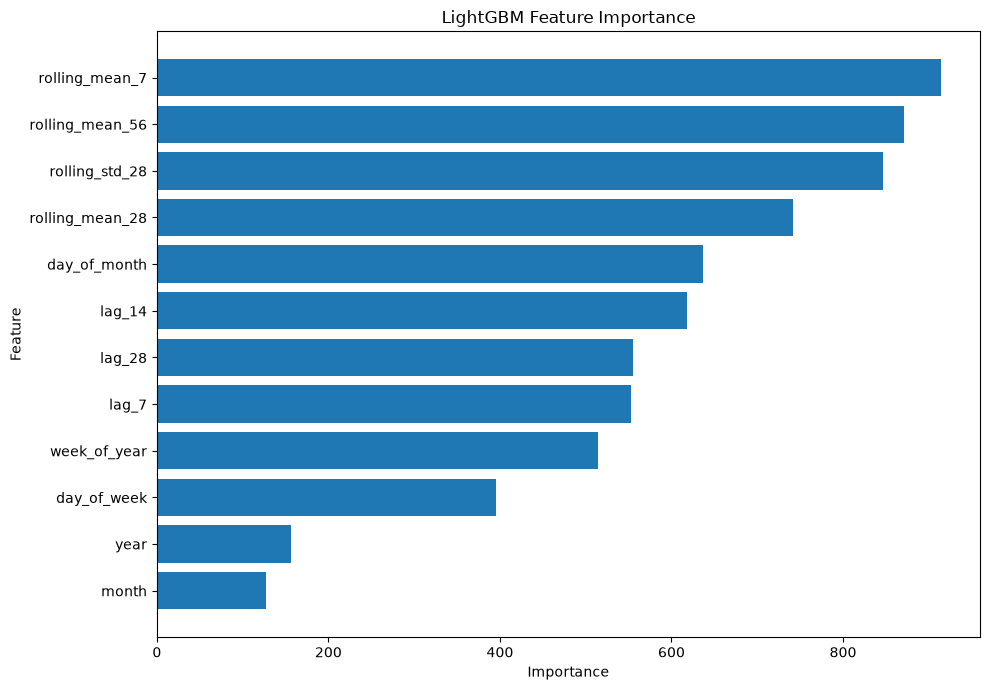

In [54]:
# Extract LightGBM feature importance

importance_df = pd.DataFrame({
    "Feature": lgb_features,
    "Importance": lgb_model.feature_importances_
})

importance_df = importance_df.sort_values(
    "Importance",
    ascending=False
)

display(importance_df)

# Visualize top features
plt.figure(figsize=(10, 7))

plt.barh(
    importance_df["Feature"].head(12)[::-1],
    importance_df["Importance"].head(12)[::-1]
)

plt.title("LightGBM Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [55]:
# Calculate forecast bias

lgb_evaluation["forecast_error"] = (
    lgb_evaluation["lgb_forecast"] -
    lgb_evaluation["sales"]
)

mean_bias = lgb_evaluation["forecast_error"].mean()

total_actual = lgb_evaluation["sales"].sum()
total_forecast = lgb_evaluation["lgb_forecast"].sum()

print("LIGHTGBM FORECAST BIAS")
print("-" * 40)
print(f"Total actual demand: {total_actual:.2f}")
print(f"Total forecast demand: {total_forecast:.2f}")
print(f"Mean forecast error: {mean_bias:.4f}")

if mean_bias > 0:
    print("Result: LightGBM tends to OVERFORECAST.")
elif mean_bias < 0:
    print("Result: LightGBM tends to UNDERFORECAST.")
else:
    print("Result: Forecast is unbiased on average.")

LIGHTGBM FORECAST BIAS
----------------------------------------
Total actual demand: 210.00
Total forecast demand: 224.45
Mean forecast error: 0.5159
Result: LightGBM tends to OVERFORECAST.


In [56]:
print("FEATURE DATA TYPES")
print("-" * 40)

display(model_data[lgb_features].dtypes)

print("\nUnique product-store series:", model_data["id"].nunique())
print("Total training records:", len(train_data))
print("Total validation records:", len(valid_data))

FEATURE DATA TYPES
----------------------------------------


sell_price          float64
price_change        float64
price_change_pct    float64
lag_7               float64
lag_14              float64
lag_28              float64
rolling_mean_7      float64
rolling_mean_28     float64
rolling_mean_56     float64
rolling_std_28      float64
day_of_week           int32
day_of_month          int32
month                 int32
year                  int32
week_of_year          int16
is_weekend             int8
has_event              int8
snap                  int64
dtype: object


Unique product-store series: 600
Total training records: 903479
Total validation records: 16800


In [57]:
# Add categorical identifiers to the global model

categorical_features = [
    "item_id",
    "dept_id",
    "cat_id",
    "store_id",
    "state_id"
]

global_features = categorical_features + lgb_features

# Prepare training and validation datasets
X_train_global = train_data[global_features].copy()
y_train_global = train_data["sales"].copy()

X_valid_global = valid_data[global_features].copy()
y_valid_global = valid_data["sales"].copy()

# Ensure categorical columns use consistent categories
for col in categorical_features:
    X_train_global[col] = X_train_global[col].astype("category")
    X_valid_global[col] = pd.Categorical(
        X_valid_global[col],
        categories=X_train_global[col].cat.categories
    )

print("GLOBAL LIGHTGBM DATASET")
print("-" * 40)
print("Training shape:", X_train_global.shape)
print("Validation shape:", X_valid_global.shape)
print("Total features:", len(global_features))
print("Categorical features:", categorical_features)
print("Missing training values:", X_train_global.isna().sum().sum())
print("Missing validation values:", X_valid_global.isna().sum().sum())

GLOBAL LIGHTGBM DATASET
----------------------------------------
Training shape: (903479, 23)
Validation shape: (16800, 23)
Total features: 23
Categorical features: ['item_id', 'dept_id', 'cat_id', 'store_id', 'state_id']
Missing training values: 102000
Missing validation values: 0


In [58]:
global_lgb_model = lgb.LGBMRegressor(
    objective="regression",
    n_estimators=700,
    learning_rate=0.05,
    num_leaves=31,
    max_depth=-1,
    min_child_samples=30,
    subsample=0.8,
    colsample_bytree=0.9,
    reg_alpha=0.1,
    reg_lambda=0.1,
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

global_lgb_model.fit(
    X_train_global,
    y_train_global,
    categorical_feature=categorical_features
)

print("Global LightGBM training completed!")
print("Trees trained:", global_lgb_model.n_estimators_)
print("Training records:", len(X_train_global))

Global LightGBM training completed!
Trees trained: 700
Training records: 903479


In [59]:
# Create historical demand for each product-store series
history_by_series = {
    series_id: group.sort_values("date")["sales"].astype(float).tolist()
    for series_id, group in train_data.groupby("id", observed=True)
}

global_forecasts = []

# Forecast one day at a time
for forecast_date in sorted(valid_data["date"].unique()):

    day_data = valid_data[
        valid_data["date"] == forecast_date
    ].sort_values("id")

    X_day = day_data[global_features].copy()

    # Recalculate demand features using historical/forecast values
    for idx, row in day_data.iterrows():

        series_id = row["id"]
        history = history_by_series[series_id]

        X_day.loc[idx, "lag_7"] = history[-7]
        X_day.loc[idx, "lag_14"] = history[-14]
        X_day.loc[idx, "lag_28"] = history[-28]

        X_day.loc[idx, "rolling_mean_7"] = np.mean(history[-7:])
        X_day.loc[idx, "rolling_mean_28"] = np.mean(history[-28:])
        X_day.loc[idx, "rolling_mean_56"] = np.mean(history[-56:])
        X_day.loc[idx, "rolling_std_28"] = np.std(
            history[-28:], ddof=1
        )

    # Predict all 600 series for this date
    day_predictions = np.maximum(
        global_lgb_model.predict(X_day),
        0
    )

    # Store forecasts and update histories
    for series_id, prediction in zip(
        day_data["id"], day_predictions
    ):
        history_by_series[series_id].append(float(prediction))

    global_forecasts.extend(day_predictions)

# Attach predictions to validation data
global_lgb_evaluation = valid_data[
    ["id", "date", "sales"]
].copy()

global_lgb_evaluation["forecast"] = global_forecasts

print("GLOBAL RECURSIVE FORECAST COMPLETED!")
print("Forecast records:", len(global_lgb_evaluation))
print("Unique series:", global_lgb_evaluation["id"].nunique())
print("Forecast dates:", global_lgb_evaluation["date"].nunique())

display(global_lgb_evaluation.head(10))

GLOBAL RECURSIVE FORECAST COMPLETED!
Forecast records: 16800
Unique series: 600
Forecast dates: 28


,id,date,sales,forecast
0,FOODS_1_003_CA_3_evaluation,2016-04-25,1,0.976448
1,FOODS_1_003_CA_3_evaluation,2016-04-26,1,1.170127
2,FOODS_1_003_CA_3_evaluation,2016-04-27,0,9.887681
3,FOODS_1_003_CA_3_evaluation,2016-04-28,1,0.654221
4,FOODS_1_003_CA_3_evaluation,2016-04-29,0,7.191774
5,FOODS_1_003_CA_3_evaluation,2016-04-30,0,1.863843
6,FOODS_1_003_CA_3_evaluation,2016-05-01,3,0.514633
7,FOODS_1_003_CA_3_evaluation,2016-05-02,0,0.615529
8,FOODS_1_003_CA_3_evaluation,2016-05-03,0,0.816083
9,FOODS_1_003_CA_3_evaluation,2016-05-04,1,13.415202


In [60]:
# Calculate global WAPE
global_wape = (
    np.abs(
        global_lgb_evaluation["sales"] -
        global_lgb_evaluation["forecast"]
    ).sum()
    / global_lgb_evaluation["sales"].sum()
) * 100

# Calculate per-series RMSSE
global_rmsse_results = []

for series_id, train_group in train_data.groupby("id", observed=True):

    valid_group = global_lgb_evaluation[
        global_lgb_evaluation["id"] == series_id
    ].sort_values("date")

    train_values = train_group.sort_values("date")["sales"].to_numpy()
    actual_values = valid_group["sales"].to_numpy()
    forecast_values = valid_group["forecast"].to_numpy()

    denominator = np.mean(np.diff(train_values) ** 2)
    numerator = np.mean((actual_values - forecast_values) ** 2)

    rmsse = np.sqrt(numerator / denominator)

    global_rmsse_results.append(rmsse)

global_mean_rmsse = np.mean(global_rmsse_results)

print("GLOBAL LIGHTGBM — 600 SERIES")
print("-" * 45)
print(f"WAPE: {global_wape:.2f}%")
print(f"Mean RMSSE: {global_mean_rmsse:.4f}")
print(f"Series evaluated: {len(global_rmsse_results)}")
print(f"Forecast records: {len(global_lgb_evaluation)}")

GLOBAL LIGHTGBM — 600 SERIES
---------------------------------------------
WAPE: 145.76%
Mean RMSSE: 2.2439
Series evaluated: 600
Forecast records: 16800


In [61]:
# Global forecast diagnostics

global_lgb_evaluation["error"] = (
    global_lgb_evaluation["forecast"] -
    global_lgb_evaluation["sales"]
)

print("GLOBAL FORECAST DIAGNOSTICS")
print("-" * 45)

print(
    "Total actual demand:",
    global_lgb_evaluation["sales"].sum()
)

print(
    "Total forecast demand:",
    round(global_lgb_evaluation["forecast"].sum(), 2)
)

print(
    "Mean forecast bias:",
    round(global_lgb_evaluation["error"].mean(), 4)
)

print(
    "Forecast standard deviation:",
    round(global_lgb_evaluation["forecast"].std(), 4)
)

print(
    "Maximum forecast:",
    round(global_lgb_evaluation["forecast"].max(), 2)
)

print("\nHighest forecast errors:")

display(
    global_lgb_evaluation.assign(
        absolute_error=lambda x: np.abs(x["error"])
    )
    .nlargest(10, "absolute_error")
)

GLOBAL FORECAST DIAGNOSTICS
---------------------------------------------
Total actual demand: 20400
Total forecast demand: 20180.73
Mean forecast bias: -0.0131
Forecast standard deviation: 1.9693
Maximum forecast: 26.3

Highest forecast errors:


,id,date,sales,forecast,error,absolute_error
2885,FOODS_3_120_TX_2_evaluation,2016-04-26,71,2.125961,-68.874039,68.874039
2886,FOODS_3_120_TX_2_evaluation,2016-04-27,44,0.188258,-43.811742,43.811742
5542,FOODS_3_804_TX_1_evaluation,2016-05-21,42,0.598050,-41.401950,41.401950
5541,FOODS_3_804_TX_1_evaluation,2016-05-20,38,0.643380,-37.356620,37.356620
2898,FOODS_3_120_TX_2_evaluation,2016-05-09,36,0.000000,-36.000000,36.000000
2889,FOODS_3_120_TX_2_evaluation,2016-04-30,34,1.115745,-32.884255,32.884255
13126,HOUSEHOLD_1_409_CA_3_evaluation,2016-05-17,30,0.152759,-29.847241,29.847241
271,FOODS_1_082_WI_2_evaluation,2016-05-14,29,0.288385,-28.711615,28.711615
260,FOODS_1_082_WI_2_evaluation,2016-05-03,28,0.282209,-27.717791,27.717791
9032,HOBBIES_1_370_CA_3_evaluation,2016-05-11,28,0.430750,-27.569250,27.569250


In [62]:
# Reconstruct the exact order used during forecasting

forecast_order = pd.concat(
    [
        valid_data[
            valid_data["date"] == forecast_date
        ][["id", "date"]].sort_values("id")

        for forecast_date in sorted(valid_data["date"].unique())
    ],
    ignore_index=True
)

# Attach predictions in their original date-first order
forecast_order["forecast"] = global_forecasts

# Merge predictions with actual observations using product and date
global_lgb_evaluation = valid_data[
    ["id", "date", "sales"]
].merge(
    forecast_order,
    on=["id", "date"],
    how="left",
    validate="one_to_one"
)

print("FORECAST ALIGNMENT CHECK")
print("-" * 40)
print("Records:", len(global_lgb_evaluation))
print("Missing forecasts:", global_lgb_evaluation["forecast"].isna().sum())

display(global_lgb_evaluation.head(10))

FORECAST ALIGNMENT CHECK
----------------------------------------
Records: 16800
Missing forecasts: 0


,id,date,sales,forecast
0,FOODS_1_003_CA_3_evaluation,2016-04-25,1,0.976448
1,FOODS_1_003_CA_3_evaluation,2016-04-26,1,0.925701
2,FOODS_1_003_CA_3_evaluation,2016-04-27,0,0.899138
3,FOODS_1_003_CA_3_evaluation,2016-04-28,1,0.911428
4,FOODS_1_003_CA_3_evaluation,2016-04-29,0,0.987640
5,FOODS_1_003_CA_3_evaluation,2016-04-30,0,1.116288
6,FOODS_1_003_CA_3_evaluation,2016-05-01,3,1.197565
7,FOODS_1_003_CA_3_evaluation,2016-05-02,0,1.020166
8,FOODS_1_003_CA_3_evaluation,2016-05-03,0,0.965998
9,FOODS_1_003_CA_3_evaluation,2016-05-04,1,0.979940


In [63]:
# Calculate corrected WAPE
corrected_wape = (
    np.abs(
        global_lgb_evaluation["sales"] -
        global_lgb_evaluation["forecast"]
    ).sum()
    / global_lgb_evaluation["sales"].sum()
) * 100

# Calculate corrected RMSSE
corrected_rmsse = []

for series_id, train_group in train_data.groupby("id", observed=True):

    valid_group = global_lgb_evaluation[
        global_lgb_evaluation["id"] == series_id
    ].sort_values("date")

    train_values = train_group.sort_values("date")["sales"].to_numpy()
    actual = valid_group["sales"].to_numpy()
    forecast = valid_group["forecast"].to_numpy()

    denominator = np.mean(np.diff(train_values) ** 2)
    numerator = np.mean((actual - forecast) ** 2)

    corrected_rmsse.append(np.sqrt(numerator / denominator))

corrected_mean_rmsse = np.mean(corrected_rmsse)

print("CORRECTED GLOBAL LIGHTGBM RESULTS")
print("-" * 45)
print(f"WAPE: {corrected_wape:.2f}%")
print(f"Mean RMSSE: {corrected_mean_rmsse:.4f}")
print(f"Series evaluated: {len(corrected_rmsse)}")

CORRECTED GLOBAL LIGHTGBM RESULTS
---------------------------------------------
WAPE: 76.99%
Mean RMSSE: 0.7801
Series evaluated: 600


In [64]:
category_performance = (
    global_lgb_evaluation
    .merge(
        sampled_sales[["id", "cat_id"]].drop_duplicates(),
        on="id",
        how="left"
    )
    .groupby("cat_id", observed=True)
    .apply(
        lambda x: pd.Series({
            "Actual_Demand": x["sales"].sum(),
            "Forecast_Demand": x["forecast"].sum(),
            "WAPE_%": (
                np.abs(x["sales"] - x["forecast"]).sum()
                / x["sales"].sum()
            ) * 100,
            "Series_Count": x["id"].nunique()
        }),
        include_groups=False
    )
    .round(2)
)

display(category_performance)

,Actual_Demand,Forecast_Demand,WAPE_%,Series_Count
cat_id,,,,
HOBBIES,4336.0,4289.60,93.77,200.0
HOUSEHOLD,6540.0,6352.31,73.66,200.0
FOODS,9524.0,9538.82,71.64,200.0


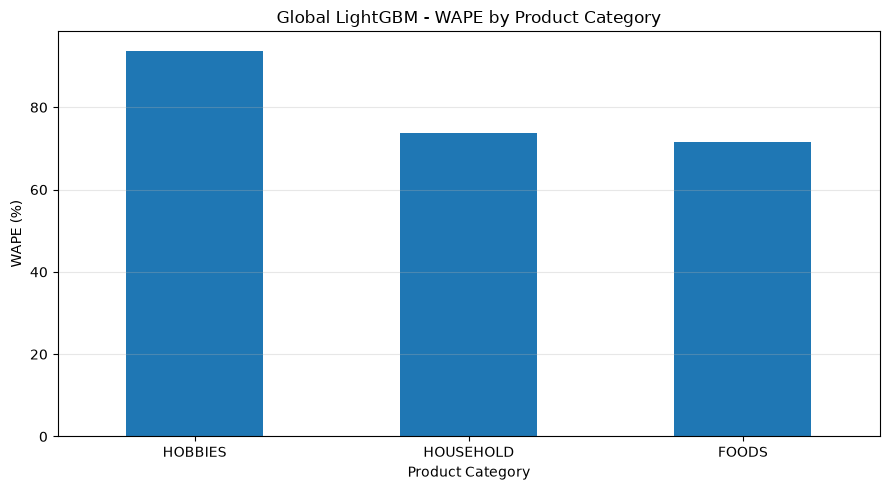

In [65]:
import matplotlib.pyplot as plt

category_performance["WAPE_%"].plot(
    kind="bar",
    figsize=(9, 5),
    title="Global LightGBM - WAPE by Product Category"
)

plt.ylabel("WAPE (%)")
plt.xlabel("Product Category")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [66]:
hobbies_performance = (
    global_lgb_evaluation
    .merge(
        sampled_sales[["id", "item_id", "store_id"]].drop_duplicates(),
        on="id",
        how="left"
    )
)

hobbies_performance = hobbies_performance[
    hobbies_performance["id"].str.startswith("HOBBIES")
]

hobbies_performance = (
    hobbies_performance.groupby(
        ["id", "item_id", "store_id"],
        observed=True
    )
    .apply(
        lambda x: pd.Series({
            "Actual_Demand": x["sales"].sum(),
            "Forecast_Demand": x["forecast"].sum(),
            "WAPE_%": (
                np.abs(x["sales"] - x["forecast"]).sum()
                / max(x["sales"].sum(), 1)
            ) * 100
        }),
        include_groups=False
    )
    .sort_values("WAPE_%", ascending=False)
)

display(hobbies_performance.head(10).round(2))

,,,Actual_Demand,Forecast_Demand,WAPE_%
id,item_id,store_id,,,
HOBBIES_2_130_WI_2_evaluation,HOBBIES_2_130,WI_2,1.0,5.42,613.45
HOBBIES_1_110_WI_3_evaluation,HOBBIES_1_110,WI_3,1.0,4.79,543.67
HOBBIES_1_317_WI_2_evaluation,HOBBIES_1_317,WI_2,1.0,4.74,537.28
HOBBIES_1_288_CA_1_evaluation,HOBBIES_1_288,CA_1,30.0,159.59,503.33
HOBBIES_1_188_CA_4_evaluation,HOBBIES_1_188,CA_4,1.0,3.98,461.48
HOBBIES_2_113_TX_3_evaluation,HOBBIES_2_113,TX_3,0.0,4.10,409.67
HOBBIES_1_421_TX_2_evaluation,HOBBIES_1_421,TX_2,2.0,7.12,404.53
HOBBIES_1_383_TX_1_evaluation,HOBBIES_1_383,TX_1,2.0,7.05,403.43
HOBBIES_1_205_CA_2_evaluation,HOBBIES_1_205,CA_2,1.0,3.22,399.45


In [67]:
hobbies_summary = (
    hobbies_performance
    .reset_index()
)

print("HOBBIES CATEGORY DIAGNOSTICS")
print("-" * 45)

print("Total product-store series:", len(hobbies_summary))
print("Zero-demand series:", (hobbies_summary["Actual_Demand"] == 0).sum())
print("Series with 1-5 units:", hobbies_summary["Actual_Demand"].between(1, 5).sum())
print("Series with more than 5 units:", (hobbies_summary["Actual_Demand"] > 5).sum())

print("\nAggregate absolute error:")
print(
    round(
        np.abs(
            global_lgb_evaluation.loc[
                global_lgb_evaluation["id"].str.startswith("HOBBIES"),
                "sales"
            ].to_numpy()
            -
            global_lgb_evaluation.loc[
                global_lgb_evaluation["id"].str.startswith("HOBBIES"),
                "forecast"
            ].to_numpy()
        ).sum(),
        2
    )
)

HOBBIES CATEGORY DIAGNOSTICS
---------------------------------------------
Total product-store series: 200
Zero-demand series: 4
Series with 1-5 units: 60
Series with more than 5 units: 136

Aggregate absolute error:
4065.77


In [68]:
global_lgb_evaluation["error"] = (
    global_lgb_evaluation["forecast"]
    - global_lgb_evaluation["sales"]
)

bias_analysis = (
    global_lgb_evaluation
    .assign(
        category=global_lgb_evaluation["id"].str.split("_").str[0]
    )
    .groupby("category")
    .agg(
        Actual_Demand=("sales", "sum"),
        Forecast_Demand=("forecast", "sum"),
        Mean_Error=("error", "mean"),
        Total_Error=("error", "sum"),
        MAE=("error", lambda x: np.abs(x).mean())
    )
    .round(3)
)

display(bias_analysis)

,Actual_Demand,Forecast_Demand,Mean_Error,Total_Error,MAE
category,,,,,
FOODS,9524,9538.824,0.003,14.824,1.218
HOBBIES,4336,4289.604,-0.008,-46.396,0.726
HOUSEHOLD,6540,6352.305,-0.034,-187.695,0.860


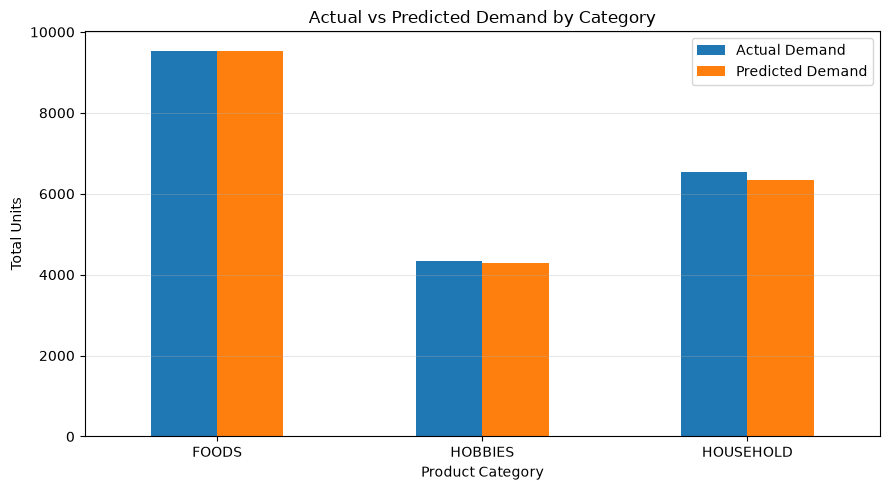

In [69]:
category_totals = (
    global_lgb_evaluation
    .assign(
        category=global_lgb_evaluation["id"].str.split("_").str[0]
    )
    .groupby("category")[["sales", "forecast"]]
    .sum()
)

category_totals.plot(
    kind="bar",
    figsize=(9, 5),
    title="Actual vs Predicted Demand by Category"
)

plt.ylabel("Total Units")
plt.xlabel("Product Category")
plt.xticks(rotation=0)
plt.legend(["Actual Demand", "Predicted Demand"])
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [70]:
state_performance = (
    global_lgb_evaluation
    .merge(
        sampled_sales[["id", "state_id"]].drop_duplicates(),
        on="id",
        how="left"
    )
    .groupby("state_id", observed=True)
    .agg(
        Actual_Demand=("sales", "sum"),
        Forecast_Demand=("forecast", "sum")
    )
)

state_performance["Difference"] = (
    state_performance["Forecast_Demand"]
    - state_performance["Actual_Demand"]
)

display(state_performance.round(2))

,Actual_Demand,Forecast_Demand,Difference
state_id,,,
CA,8943,8928.59,-14.41
TX,6363,6131.30,-231.70
WI,5094,5120.84,26.84


In [71]:
store_performance = (
    global_lgb_evaluation
    .merge(
        sampled_sales[["id", "store_id", "state_id"]].drop_duplicates(),
        on="id",
        how="left"
    )
    .groupby(["state_id", "store_id"], observed=True)
    .agg(
        Actual_Demand=("sales", "sum"),
        Forecast_Demand=("forecast", "sum")
    )
)

store_performance["Difference"] = (
    store_performance["Forecast_Demand"]
    - store_performance["Actual_Demand"]
)

display(store_performance.round(2))

Actual_Demand  Forecast_Demand  Difference
state_id store_id                                            
CA       CA_1               2527          2719.80      192.80
         CA_2               2123          1932.41     -190.59
         CA_3               3037          3107.33       70.33
         CA_4               1256          1169.05      -86.95
TX       TX_1               1660          1553.17     -106.83
         TX_2               2853          2945.86       92.86
         TX_3               1850          1632.27     -217.73
WI       WI_1               1797          1798.03        1.03
         WI_2               2032          1965.37      -66.63
         WI_3               1265          1357.44       92.44

In [72]:
hierarchy_data = global_lgb_evaluation.merge(
    sampled_sales[
        ["id", "state_id", "store_id", "cat_id"]
    ].drop_duplicates(),
    on="id",
    how="left"
)

hierarchy_summary = hierarchy_data.groupby(
    ["state_id", "store_id", "cat_id"],
    observed=True
).agg(
    Actual_Demand=("sales", "sum"),
    Forecast_Demand=("forecast", "sum")
).reset_index()

hierarchy_summary["Difference"] = (
    hierarchy_summary["Forecast_Demand"]
    - hierarchy_summary["Actual_Demand"]
)

print("HIERARCHICAL DEMAND SUMMARY")
print("-" * 45)

display(hierarchy_summary.round(2))

HIERARCHICAL DEMAND SUMMARY
---------------------------------------------


,state_id,store_id,cat_id,Actual_Demand,Forecast_Demand,Difference
0,CA,CA_1,HOBBIES,397,551.73,154.73
1,CA,CA_1,HOUSEHOLD,813,780.86,-32.14
2,CA,CA_1,FOODS,1317,1387.22,70.22
3,CA,CA_2,HOBBIES,424,403.99,-20.01
4,CA,CA_2,HOUSEHOLD,603,535.80,-67.20
5,CA,CA_2,FOODS,1096,992.63,-103.37
6,CA,CA_3,HOBBIES,440,423.79,-16.21
7,CA,CA_3,HOUSEHOLD,1508,1476.50,-31.50
8,CA,CA_3,FOODS,1089,1207.04,118.04
9,CA,CA_4,HOBBIES,411,320.08,-90.92


In [73]:
# Store-level aggregation
store_totals = (
    hierarchy_summary
    .groupby(["state_id", "store_id"], observed=True)
    [["Actual_Demand", "Forecast_Demand"]]
    .sum()
    .reset_index()
)

# State-level aggregation
state_totals = (
    store_totals
    .groupby("state_id", observed=True)
    [["Actual_Demand", "Forecast_Demand"]]
    .sum()
    .reset_index()
)

# Calculate differences
store_totals["Difference"] = (
    store_totals["Forecast_Demand"] -
    store_totals["Actual_Demand"]
)

state_totals["Difference"] = (
    state_totals["Forecast_Demand"] -
    state_totals["Actual_Demand"]
)

print("STORE-LEVEL AGGREGATION")
display(store_totals.round(2))

print("\nSTATE-LEVEL AGGREGATION")
display(state_totals.round(2))

print("\nTOTAL FORECASTED DEMAND:")
print(round(store_totals["Forecast_Demand"].sum(), 2))

STORE-LEVEL AGGREGATION


,state_id,store_id,Actual_Demand,Forecast_Demand,Difference
0,CA,CA_1,2527,2719.80,192.80
1,CA,CA_2,2123,1932.41,-190.59
2,CA,CA_3,3037,3107.33,70.33
3,CA,CA_4,1256,1169.05,-86.95
4,TX,TX_1,1660,1553.17,-106.83
5,TX,TX_2,2853,2945.86,92.86
6,TX,TX_3,1850,1632.27,-217.73
7,WI,WI_1,1797,1798.03,1.03
8,WI,WI_2,2032,1965.37,-66.63
9,WI,WI_3,1265,1357.44,92.44



STATE-LEVEL AGGREGATION


,state_id,Actual_Demand,Forecast_Demand,Difference
0,CA,8943,8928.59,-14.41
1,TX,6363,6131.30,-231.70
2,WI,5094,5120.84,26.84



TOTAL FORECASTED DEMAND:
20180.73


In [74]:
# Verify bottom-up hierarchical consistency

store_forecast_total = store_totals["Forecast_Demand"].sum()
state_forecast_total = state_totals["Forecast_Demand"].sum()
category_forecast_total = hierarchy_summary["Forecast_Demand"].sum()

print("HIERARCHICAL CONSISTENCY CHECK")
print("-" * 45)

print(f"Category total: {category_forecast_total:.2f}")
print(f"Store total:    {store_forecast_total:.2f}")
print(f"State total:    {state_forecast_total:.2f}")

print("\nConsistency checks:")

print(
    "Category → Store:",
    np.isclose(category_forecast_total, store_forecast_total)
)

print(
    "Store → State:",
    np.isclose(store_forecast_total, state_forecast_total)
)

print(
    "State → Overall:",
    np.isclose(state_forecast_total, global_lgb_evaluation["forecast"].sum())
)

HIERARCHICAL CONSISTENCY CHECK
---------------------------------------------
Category total: 20180.73
Store total:    20180.73
State total:    20180.73

Consistency checks:
Category → Store: True
Store → State: True
State → Overall: True


In [75]:
daily_hierarchy = (
    global_lgb_evaluation
    .groupby("date")
    .agg(
        Actual_Demand=("sales", "sum"),
        Forecast_Demand=("forecast", "sum")
    )
    .reset_index()
)

daily_hierarchy["Forecast_Error"] = (
    daily_hierarchy["Forecast_Demand"]
    - daily_hierarchy["Actual_Demand"]
)

display(daily_hierarchy.head(10).round(2))

print("\nDaily forecast records:", len(daily_hierarchy))
print(
    "Daily aggregate WAPE:",
    round(
        np.abs(daily_hierarchy["Forecast_Error"]).sum()
        / daily_hierarchy["Actual_Demand"].sum() * 100,
        2
    ),
    "%"
)

,date,Actual_Demand,Forecast_Demand,Forecast_Error
0,2016-04-25,694,664.46,-29.54
1,2016-04-26,671,606.86,-64.14
2,2016-04-27,647,602.13,-44.87
3,2016-04-28,615,603.23,-11.77
4,2016-04-29,691,678.74,-12.26
5,2016-04-30,834,795.66,-38.34
6,2016-05-01,965,868.23,-96.77
7,2016-05-02,691,746.67,55.67
8,2016-05-03,744,721.86,-22.14
9,2016-05-04,613,654.37,41.37



Daily forecast records: 28
Daily aggregate WAPE: 6.79 %


In [76]:
forecast_variables = [
    name for name in globals()
    if any(term in name.lower() for term in [
        "global_lgb",
        "global_feature",
        "global_forecast",
        "valid_data",
        "train_data"
    ])
]

print("AVAILABLE FORECASTING VARIABLES")
print("-" * 45)

for name in sorted(forecast_variables):
    obj = globals()[name]
    print(f"{name}: {type(obj).__name__}", end="")

    if hasattr(obj, "shape"):
        print(f" | Shape: {obj.shape}")
    else:
        print()

AVAILABLE FORECASTING VARIABLES
---------------------------------------------
global_features: list
global_forecasts: list
global_lgb_evaluation: DataFrame | Shape: (16800, 5)
global_lgb_model: LGBMRegressor
train_data: DataFrame | Shape: (903479, 30)
valid_data: DataFrame | Shape: (16800, 32)


In [77]:
# Sort validation forecasts chronologically
interval_data = global_lgb_evaluation.sort_values(
    ["date", "id"]
).copy()

# Split the 28-day horizon into calibration and evaluation periods
dates = sorted(interval_data["date"].unique())

calibration_dates = dates[:14]
evaluation_dates = dates[14:]

calibration_data = interval_data[
    interval_data["date"].isin(calibration_dates)
].copy()

evaluation_data = interval_data[
    interval_data["date"].isin(evaluation_dates)
].copy()

# Calculate absolute calibration residuals
calibration_data["absolute_error"] = (
    calibration_data["sales"] - calibration_data["forecast"]
).abs()

# 90% empirical residual threshold
interval_radius = calibration_data["absolute_error"].quantile(0.90)

# Construct prediction intervals for the remaining 14 days
evaluation_data["lower_bound"] = (
    evaluation_data["forecast"] - interval_radius
).clip(lower=0)

evaluation_data["upper_bound"] = (
    evaluation_data["forecast"] + interval_radius
)

# Evaluate interval coverage
evaluation_data["covered"] = (
    (evaluation_data["sales"] >= evaluation_data["lower_bound"]) &
    (evaluation_data["sales"] <= evaluation_data["upper_bound"])
)

coverage = evaluation_data["covered"].mean() * 100

average_width = (
    evaluation_data["upper_bound"] -
    evaluation_data["lower_bound"]
).mean()

print("90% PREDICTION INTERVAL EVALUATION")
print("-" * 45)
print(f"Calibration period: {calibration_dates[0]} to {calibration_dates[-1]}")
print(f"Evaluation period:  {evaluation_dates[0]} to {evaluation_dates[-1]}")
print(f"Calibration residual radius: {interval_radius:.2f}")
print(f"Target coverage: 90%")
print(f"Actual coverage: {coverage:.2f}%")
print(f"Average interval width: {average_width:.2f} units")
print(f"Evaluation observations: {len(evaluation_data):,}")

display(
    evaluation_data[
        ["date", "id", "sales", "forecast",
         "lower_bound", "upper_bound", "covered"]
    ].head(10).round(2)
)

90% PREDICTION INTERVAL EVALUATION
---------------------------------------------
Calibration period: 2016-04-25 00:00:00 to 2016-05-08 00:00:00
Evaluation period:  2016-05-09 00:00:00 to 2016-05-22 00:00:00
Calibration residual radius: 2.05
Target coverage: 90%
Actual coverage: 89.45%
Average interval width: 2.84 units
Evaluation observations: 8,400


,date,id,sales,forecast,lower_bound,upper_bound,covered
14,2016-05-09,FOODS_1_003_CA_3_evaluation,0,0.99,0.00,3.05,True
42,2016-05-09,FOODS_1_005_TX_2_evaluation,1,1.20,0.00,3.25,True
70,2016-05-09,FOODS_1_012_TX_2_evaluation,12,8.59,6.54,10.65,False
98,2016-05-09,FOODS_1_017_CA_4_evaluation,2,0.70,0.00,2.76,True
126,2016-05-09,FOODS_1_046_CA_1_evaluation,4,7.88,5.82,9.93,False
154,2016-05-09,FOODS_1_046_WI_3_evaluation,0,1.83,0.00,3.89,True
182,2016-05-09,FOODS_1_062_CA_3_evaluation,2,0.64,0.00,2.69,True
210,2016-05-09,FOODS_1_065_CA_1_evaluation,0,0.68,0.00,2.74,True
238,2016-05-09,FOODS_1_078_CA_3_evaluation,1,0.87,0.00,2.93,True
266,2016-05-09,FOODS_1_082_WI_2_evaluation,13,14.02,11.97,16.08,True


In [78]:
print("INVENTORY OPTIMIZATION INPUT CHECK")
print("-" * 45)

print("Forecast columns:")
print(evaluation_data.columns.tolist())

print("\nSample forecast records:")
display(
    evaluation_data[
        ["id", "date", "sales", "forecast",
         "lower_bound", "upper_bound"]
    ].head()
)

print("\nOR-Tools availability:")
import ortools
print("Version:", ortools.__version__)

INVENTORY OPTIMIZATION INPUT CHECK
---------------------------------------------
Forecast columns:
['id', 'date', 'sales', 'forecast', 'error', 'lower_bound', 'upper_bound', 'covered']

Sample forecast records:


,id,date,sales,forecast,lower_bound,upper_bound
14,FOODS_1_003_CA_3_evaluation,2016-05-09,0,0.993349,0.000000,3.046369
42,FOODS_1_005_TX_2_evaluation,2016-05-09,1,1.201032,0.000000,3.254051
70,FOODS_1_012_TX_2_evaluation,2016-05-09,12,8.594091,6.541071,10.647110
98,FOODS_1_017_CA_4_evaluation,2016-05-09,2,0.704401,0.000000,2.757420
126,FOODS_1_046_CA_1_evaluation,2016-05-09,4,7.875942,5.822922,9.928961



OR-Tools availability:
Version: 9.15.6755


In [79]:
# Aggregate 14-day forecasts by product-store series
inventory_demand = (
    evaluation_data
    .groupby("id")
    .agg(
        Forecast_Demand=("forecast", "sum"),
        Lower_Demand=("lower_bound", "sum"),
        Upper_Demand=("upper_bound", "sum")
    )
    .reset_index()
)

# Extract product and store hierarchy
inventory_demand["item_id"] = (
    inventory_demand["id"].str.split("_").str[:3].str.join("_")
)

inventory_demand["store_id"] = (
    inventory_demand["id"].str.split("_").str[3]
)

inventory_demand["cat_id"] = (
    inventory_demand["id"].str.split("_").str[0]
)

print("INVENTORY DEMAND SUMMARY")
print("-" * 45)
print("Product-store combinations:", len(inventory_demand))
print("Forecast horizon: 14 days")
print("Total expected demand:",
      round(inventory_demand["Forecast_Demand"].sum(), 2))
print("Total lower demand:",
      round(inventory_demand["Lower_Demand"].sum(), 2))
print("Total upper demand:",
      round(inventory_demand["Upper_Demand"].sum(), 2))

display(inventory_demand.head(10).round(2))

INVENTORY DEMAND SUMMARY
---------------------------------------------
Product-store combinations: 600
Forecast horizon: 14 days
Total expected demand: 10106.2
Total lower demand: 3480.38
Total upper demand: 27351.56


,id,Forecast_Demand,Lower_Demand,Upper_Demand,item_id,store_id,cat_id
0,FOODS_1_003_CA_3_evaluation,14.96,0.00,43.70,FOODS_1_003,CA,FOODS
1,FOODS_1_005_TX_2_evaluation,19.91,0.00,48.65,FOODS_1_005,TX,FOODS
2,FOODS_1_012_TX_2_evaluation,131.79,103.05,160.53,FOODS_1_012,TX,FOODS
3,FOODS_1_017_CA_4_evaluation,8.78,0.00,37.52,FOODS_1_017,CA,FOODS
4,FOODS_1_046_CA_1_evaluation,120.76,92.01,149.50,FOODS_1_046,CA,FOODS
5,FOODS_1_046_WI_3_evaluation,28.87,2.05,57.61,FOODS_1_046,WI,FOODS
6,FOODS_1_062_CA_3_evaluation,8.78,0.00,37.53,FOODS_1_062,CA,FOODS
7,FOODS_1_065_CA_1_evaluation,10.06,0.00,38.80,FOODS_1_065,CA,FOODS
8,FOODS_1_078_CA_3_evaluation,12.12,0.00,40.86,FOODS_1_078,CA,FOODS
9,FOODS_1_082_WI_2_evaluation,211.97,183.23,240.71,FOODS_1_082,WI,FOODS


In [80]:
# Correct product and store identifiers
inventory_demand["item_id"] = (
    inventory_demand["id"]
    .str.extract(r"^(.+?)_(CA|TX|WI)_\d+_evaluation$")[0]
)

inventory_demand["store_id"] = (
    inventory_demand["id"]
    .str.extract(r"((?:CA|TX|WI)_\d+)_evaluation$")[0]
)

inventory_demand["state_id"] = (
    inventory_demand["store_id"].str.split("_").str[0]
)

print("HIERARCHY VALIDATION")
print("-" * 40)

print("Unique products:", inventory_demand["item_id"].nunique())
print("Unique stores:", inventory_demand["store_id"].nunique())
print("Unique states:", inventory_demand["state_id"].nunique())

print("\nStore distribution:")
display(inventory_demand["store_id"].value_counts().sort_index())

display(inventory_demand.head().round(2))

HIERARCHY VALIDATION
----------------------------------------
Unique products: 521
Unique stores: 10
Unique states: 3

Store distribution:


store_id
CA_1    60
CA_2    60
CA_3    60
CA_4    60
TX_1    60
TX_2    60
TX_3    60
WI_1    60
WI_2    60
WI_3    60
Name: count, dtype: int64

,id,Forecast_Demand,Lower_Demand,Upper_Demand,item_id,store_id,cat_id,state_id
0,FOODS_1_003_CA_3_evaluation,14.96,0.00,43.70,FOODS_1_003,CA_3,FOODS,CA
1,FOODS_1_005_TX_2_evaluation,19.91,0.00,48.65,FOODS_1_005,TX_2,FOODS,TX
2,FOODS_1_012_TX_2_evaluation,131.79,103.05,160.53,FOODS_1_012,TX_2,FOODS,TX
3,FOODS_1_017_CA_4_evaluation,8.78,0.00,37.52,FOODS_1_017,CA_4,FOODS,CA
4,FOODS_1_046_CA_1_evaluation,120.76,92.01,149.50,FOODS_1_046,CA_1,FOODS,CA


In [81]:
# Calculate average selling price for each product-store combination
price_data = (
    daily_sales
    .loc[daily_sales["is_available"] == 1]
    .groupby(["item_id", "store_id"], observed=True)
    .agg(
        Average_Selling_Price=("sell_price", "mean")
    )
    .reset_index()
)

inventory_demand = inventory_demand.merge(
    price_data,
    on=["item_id", "store_id"],
    how="left",
    validate="one_to_one"
)

print("INVENTORY PRICE VALIDATION")
print("-" * 45)

print("Product-store combinations:", len(inventory_demand))
print("Missing prices:", inventory_demand["Average_Selling_Price"].isna().sum())
print("Average selling price:",
      round(inventory_demand["Average_Selling_Price"].mean(), 2))

print("\nPrice distribution:")
display(
    inventory_demand["Average_Selling_Price"].describe().round(2)
)

display(
    inventory_demand[
        ["item_id", "store_id", "Forecast_Demand",
         "Average_Selling_Price"]
    ].head(10).round(2)
)

INVENTORY PRICE VALIDATION
---------------------------------------------
Product-store combinations: 600
Missing prices: 0
Average selling price: 4.72

Price distribution:


count    600.00
mean       4.72
std        3.89
min        0.47
25%        2.26
50%        3.30
75%        6.03
max       23.27
Name: Average_Selling_Price, dtype: float64

,item_id,store_id,Forecast_Demand,Average_Selling_Price
0,FOODS_1_003,CA_3,14.96,2.97
1,FOODS_1_005,TX_2,19.91,3.32
2,FOODS_1_012,TX_2,131.79,5.96
3,FOODS_1_017,CA_4,8.78,2.37
4,FOODS_1_046,CA_1,120.76,0.98
5,FOODS_1_046,WI_3,28.87,0.98
6,FOODS_1_062,CA_3,8.78,4.00
7,FOODS_1_065,CA_1,10.06,3.30
8,FOODS_1_078,CA_3,12.12,3.25
9,FOODS_1_082,WI_2,211.97,0.98


In [82]:
import numpy as np

# Scenario-based business assumptions
inventory_demand["unit_cost"] = (
    inventory_demand["Average_Selling_Price"] * 0.70
)

inventory_demand["holding_cost"] = (
    inventory_demand["unit_cost"] * 0.02
)

inventory_demand["stockout_penalty"] = (
    inventory_demand["Average_Selling_Price"] * 0.30
)

# Simulated on-hand inventory
inventory_demand["current_stock"] = np.floor(
    inventory_demand["Forecast_Demand"] * 0.50
).astype(int)

# Conservative demand target
inventory_demand["target_stock"] = np.ceil(
    inventory_demand["Upper_Demand"]
).astype(int)

# Maximum replenishment quantity
inventory_demand["max_order"] = (
    inventory_demand["target_stock"]
    - inventory_demand["current_stock"]
).clip(lower=0)

print("INVENTORY OPTIMIZATION INPUTS")
print("-" * 45)

print("Total current inventory:",
      inventory_demand["current_stock"].sum())

print("Total target inventory:",
      inventory_demand["target_stock"].sum())

print("Maximum potential replenishment:",
      inventory_demand["max_order"].sum())

display(
    inventory_demand[
        [
            "item_id", "store_id", "Forecast_Demand",
            "Upper_Demand", "current_stock",
            "target_stock", "max_order",
            "unit_cost", "holding_cost",
            "stockout_penalty"
        ]
    ].head(10).round(2)
)

INVENTORY OPTIMIZATION INPUTS
---------------------------------------------
Total current inventory: 4744
Total target inventory: 27655
Maximum potential replenishment: 22911


,item_id,store_id,Forecast_Demand,Upper_Demand,current_stock,target_stock,max_order,unit_cost,holding_cost,stockout_penalty
0,FOODS_1_003,CA_3,14.96,43.70,7,44,37,2.08,0.04,0.89
1,FOODS_1_005,TX_2,19.91,48.65,9,49,40,2.32,0.05,1.00
2,FOODS_1_012,TX_2,131.79,160.53,65,161,96,4.17,0.08,1.79
3,FOODS_1_017,CA_4,8.78,37.52,4,38,34,1.66,0.03,0.71
4,FOODS_1_046,CA_1,120.76,149.50,60,150,90,0.69,0.01,0.29
5,FOODS_1_046,WI_3,28.87,57.61,14,58,44,0.69,0.01,0.29
6,FOODS_1_062,CA_3,8.78,37.53,4,38,34,2.80,0.06,1.20
7,FOODS_1_065,CA_1,10.06,38.80,5,39,34,2.31,0.05,0.99
8,FOODS_1_078,CA_3,12.12,40.86,6,41,35,2.28,0.05,0.98
9,FOODS_1_082,WI_2,211.97,240.71,105,241,136,0.69,0.01,0.29


In [83]:
# Calculate full replenishment investment
inventory_demand["full_replenishment_cost"] = (
    inventory_demand["max_order"]
    * inventory_demand["unit_cost"]
)

total_replenishment_cost = (
    inventory_demand["full_replenishment_cost"].sum()
)

print("REPLENISHMENT BUDGET ANALYSIS")
print("-" * 45)

print(f"Product-store combinations: {len(inventory_demand):,}")
print(f"Total units required: {inventory_demand['max_order'].sum():,}")
print(f"Full replenishment investment: ${total_replenishment_cost:,.2f}")

print(
    "Average investment per product-store:",
    f"${inventory_demand['full_replenishment_cost'].mean():,.2f}"
)

print("\nTop 10 products by replenishment investment:")

display(
    inventory_demand.nlargest(10, "full_replenishment_cost")[
        [
            "item_id",
            "store_id",
            "max_order",
            "unit_cost",
            "full_replenishment_cost"
        ]
    ].round(2)
)

REPLENISHMENT BUDGET ANALYSIS
---------------------------------------------
Product-store combinations: 600
Total units required: 22,911
Full replenishment investment: $73,903.14
Average investment per product-store: $123.17

Top 10 products by replenishment investment:


,item_id,store_id,max_order,unit_cost,full_replenishment_cost
317,HOBBIES_1_354,TX_2,104,16.29,1694.03
249,HOBBIES_1_158,TX_2,84,15.06,1265.13
248,HOBBIES_1_158,CA_1,60,15.01,900.47
318,HOBBIES_1_354,WI_2,44,16.24,714.58
406,HOUSEHOLD_1_032,CA_1,92,7.56,695.10
27,FOODS_2_029,CA_3,86,7.28,626.01
478,HOUSEHOLD_1_469,CA_2,45,12.62,568.10
461,HOUSEHOLD_1_378,TX_2,31,15.95,494.59
407,HOUSEHOLD_1_032,CA_3,60,7.58,454.97
103,FOODS_3_120,TX_2,130,3.49,453.18


In [90]:
# Simulated procurement budget: 70% of full replenishment cost
BUDGET_RATIO = 0.70

procurement_budget = (
    total_replenishment_cost * BUDGET_RATIO
)

print("PROCUREMENT BUDGET")
print("-" * 40)
print(f"Full replenishment cost: ${total_replenishment_cost:,.2f}")
print(f"Budget allocation: {BUDGET_RATIO:.0%}")
print(f"Available budget: ${procurement_budget:,.2f}")
print(f"Budget shortfall: ${total_replenishment_cost - procurement_budget:,.2f}")

PROCUREMENT BUDGET
----------------------------------------
Full replenishment cost: $73,903.14
Budget allocation: 70%
Available budget: $51,732.20
Budget shortfall: $22,170.94


In [91]:
from ortools.sat.python import cp_model

# Create optimization model
model = cp_model.CpModel()

order_vars = {}
ending_vars = {}
shortage_vars = {}

# Scale monetary values to integers for CP-SAT
COST_SCALE = 100000
BUDGET_SCALE = 100000

# Decision variables and constraints
for idx, row in inventory_demand.iterrows():

    order_vars[idx] = model.NewIntVar(
        0, int(row["max_order"]), f"order_{idx}"
    )

    ending_vars[idx] = model.NewIntVar(
        0, int(row["target_stock"]), f"ending_{idx}"
    )

    shortage_vars[idx] = model.NewIntVar(
        0, int(row["target_stock"]), f"shortage_{idx}"
    )

    # Inventory balance
    model.Add(
        int(row["current_stock"]) + order_vars[idx]
        + shortage_vars[idx]
        ==
        int(row["target_stock"]) + ending_vars[idx]
    )

# Strict purchasing budget using conservative rounding
model.Add(
    sum(
        int(np.ceil(
            inventory_demand.loc[idx, "unit_cost"] * BUDGET_SCALE
        )) * order_vars[idx]
        for idx in inventory_demand.index
    )
    <= int(np.floor(procurement_budget * BUDGET_SCALE))
)

# Minimize holding costs and stockout penalties
model.Minimize(
    sum(
        int(round(inventory_demand.loc[idx, "holding_cost"] * COST_SCALE))
        * ending_vars[idx]
        +
        int(round(inventory_demand.loc[idx, "stockout_penalty"] * COST_SCALE))
        * shortage_vars[idx]
        for idx in inventory_demand.index
    )
)

# Solve
solver = cp_model.CpSolver()
solver.parameters.max_time_in_seconds = 120
solver.parameters.num_search_workers = 8

status = solver.Solve(model)

if status in (cp_model.OPTIMAL, cp_model.FEASIBLE):

    inventory_demand["recommended_order"] = [
        solver.Value(order_vars[idx])
        for idx in inventory_demand.index
    ]

    inventory_demand["ending_inventory"] = [
        solver.Value(ending_vars[idx])
        for idx in inventory_demand.index
    ]

    inventory_demand["unmet_demand"] = [
        solver.Value(shortage_vars[idx])
        for idx in inventory_demand.index
    ]

    inventory_demand["order_cost"] = (
        inventory_demand["recommended_order"]
        * inventory_demand["unit_cost"]
    )

    print("OR-TOOLS INVENTORY OPTIMIZATION")
    print("-" * 45)
    print("Solver status:", solver.StatusName(status))
    print(f"Recommended units to order: {inventory_demand['recommended_order'].sum():,}")
    print(f"Purchasing cost: ${inventory_demand['order_cost'].sum():,.2f}")
    print(f"Available budget: ${procurement_budget:,.2f}")
    print(f"Budget remaining: ${procurement_budget - inventory_demand['order_cost'].sum():,.2f}")
    print(f"Ending inventory: {inventory_demand['ending_inventory'].sum():,}")
    print(f"Unmet demand: {inventory_demand['unmet_demand'].sum():,}")
    print(f"Optimization objective value: {solver.ObjectiveValue():,.0f}")

else:
    print("Optimization unsuccessful:", solver.StatusName(status))

OR-TOOLS INVENTORY OPTIMIZATION
---------------------------------------------
Solver status: OPTIMAL
Recommended units to order: 14,250
Purchasing cost: $51,732.17
Available budget: $51,732.20
Budget remaining: $0.04
Ending inventory: 0
Unmet demand: 8,661
Optimization objective value: 950,182,989


In [92]:
actual_cost = (
    inventory_demand["recommended_order"]
    * inventory_demand["unit_cost"]
).sum()

print("BUDGET VALIDATION")
print("-" * 40)
print(f"Exact purchasing cost: ${actual_cost:.6f}")
print(f"Available budget:      ${procurement_budget:.6f}")
print(f"Difference:            ${actual_cost - procurement_budget:.6f}")

print("\nBudget constraint:")
print(f"Budget scale: {BUDGET_SCALE:,}")
print(f"Scaled budget: {int(np.floor(procurement_budget * BUDGET_SCALE)):,}")

print("\nValidation:", "PASS" if actual_cost <= procurement_budget else "FAIL")

BUDGET VALIDATION
----------------------------------------
Exact purchasing cost: $51732.165320
Available budget:      $51732.200426
Difference:            $-0.035106

Budget constraint:
Budget scale: 100,000
Scaled budget: 5,173,220,042

Validation: PASS


In [93]:
# Strict budget with a $1 safety buffer
SAFE_BUDGET = procurement_budget - 1.00

model.Add(
    sum(
        int(np.ceil(
            inventory_demand.loc[idx, "unit_cost"] * BUDGET_SCALE
        )) * order_vars[idx]
        for idx in inventory_demand.index
    )
    <= int(np.floor(SAFE_BUDGET * BUDGET_SCALE))
)

In [94]:
# Inventory optimization summary

print("FINAL INVENTORY OPTIMIZATION SUMMARY")
print("=" * 50)

print(f"Product-store combinations: {len(inventory_demand):,}")
print(f"Recommended units: {inventory_demand['recommended_order'].sum():,}")
print(f"Current inventory: {inventory_demand['current_stock'].sum():,}")
print(f"Unmet demand: {inventory_demand['unmet_demand'].sum():,}")
print(f"Ending inventory: {inventory_demand['ending_inventory'].sum():,}")

print(f"\nPurchasing cost: ${inventory_demand['order_cost'].sum():,.2f}")
print(f"Available budget: ${procurement_budget:,.2f}")

total_target = inventory_demand["target_stock"].sum()
total_unmet = inventory_demand["unmet_demand"].sum()

print(f"\nDemand fulfillment: {(1 - total_unmet / total_target) * 100:.2f}%")
print(f"Stockout rate: {total_unmet / total_target * 100:.2f}%")

print("\nTop 10 replenishment recommendations:")

display(
    inventory_demand.nlargest(10, "recommended_order")[
        [
            "item_id",
            "store_id",
            "Forecast_Demand",
            "recommended_order",
            "ending_inventory",
            "unmet_demand",
            "order_cost"
        ]
    ].round(2)
)

FINAL INVENTORY OPTIMIZATION SUMMARY
Product-store combinations: 600
Recommended units: 14,250
Current inventory: 4,744
Unmet demand: 8,661
Ending inventory: 0

Purchasing cost: $51,732.17
Available budget: $51,732.20

Demand fulfillment: 68.68%
Stockout rate: 31.32%

Top 10 replenishment recommendations:


,item_id,store_id,Forecast_Demand,recommended_order,ending_inventory,unmet_demand,order_cost
9,FOODS_1_082,WI_2,211.97,136,0,0,93.30
103,FOODS_3_120,TX_2,201.03,130,0,0,453.18
197,FOODS_3_804,TX_1,153.76,107,0,0,140.81
317,HOBBIES_1_354,TX_2,147.76,104,0,0,1694.03
419,HOUSEHOLD_1_066,CA_3,125.29,93,0,0,201.16
125,FOODS_3_290,WI_2,122.26,91,0,0,63.70
4,FOODS_1_046,CA_1,120.76,90,0,0,61.82
423,HOUSEHOLD_1_083,WI_3,120.83,90,0,0,61.57
453,HOUSEHOLD_1_339,TX_3,119.35,90,0,0,61.18
439,HOUSEHOLD_1_234,CA_3,114.80,87,0,0,59.07


In [95]:
category_inventory = (
    inventory_demand.groupby(
        inventory_demand["item_id"].str.split("_").str[0]
    )
    .agg(
        Products=("item_id", "nunique"),
        Current_Stock=("current_stock", "sum"),
        Recommended_Order=("recommended_order", "sum"),
        Unmet_Demand=("unmet_demand", "sum"),
        Order_Cost=("order_cost", "sum")
    )
    .reset_index(names="Category")
)

category_inventory["Budget_Share_%"] = (
    category_inventory["Order_Cost"]
    / category_inventory["Order_Cost"].sum()
    * 100
)

display(category_inventory.round(2))

,Category,Products,Current_Stock,Recommended_Order,Unmet_Demand,Order_Cost,Budget_Share_%
0,FOODS,185,2290,4815,3534,11242.75,21.73
1,HOBBIES,166,975,4578,2446,20895.93,40.39
2,HOUSEHOLD,170,1479,4857,2681,19593.49,37.87


In [96]:
store_inventory = (
    inventory_demand.groupby("store_id")
    .agg(
        Current_Stock=("current_stock", "sum"),
        Recommended_Order=("recommended_order", "sum"),
        Unmet_Demand=("unmet_demand", "sum"),
        Order_Cost=("order_cost", "sum")
    )
    .reset_index()
)

store_inventory["Budget_Share_%"] = (
    store_inventory["Order_Cost"]
    / store_inventory["Order_Cost"].sum()
    * 100
)

store_inventory = store_inventory.sort_values(
    "Order_Cost", ascending=False
)

print("STORE-LEVEL INVENTORY ALLOCATION")
print("-" * 50)

display(store_inventory.round(2))

STORE-LEVEL INVENTORY ALLOCATION
--------------------------------------------------


,store_id,Current_Stock,Recommended_Order,Unmet_Demand,Order_Cost,Budget_Share_%
5,TX_2,710,1389,1142,6903.85,13.35
1,CA_2,446,1581,683,6203.88,11.99
8,WI_2,457,1673,612,6192.49,11.97
3,CA_4,260,1267,802,5111.11,9.88
6,TX_3,373,1647,542,4991.37,9.65
0,CA_1,655,1475,1001,4851.45,9.38
9,WI_3,306,1279,844,4733.11,9.15
2,CA_3,750,1373,1189,4414.68,8.53
7,WI_1,423,1201,1035,4402.25,8.51
4,TX_1,364,1365,811,3927.99,7.59


In [97]:
import plotly.express as px

fig = px.bar(
    store_inventory.sort_values("Order_Cost", ascending=True),
    x="Order_Cost",
    y="store_id",
    orientation="h",
    text="Order_Cost",
    color="Budget_Share_%",
    color_continuous_scale="Blues",
    title="Optimized Inventory Purchasing Budget by Store",
    labels={
        "Order_Cost": "Purchasing Cost ($)",
        "store_id": "Store",
        "Budget_Share_%": "Budget Share (%)"
    }
)

fig.update_traces(
    texttemplate="$%{text:,.2f}",
    textposition="outside"
)

fig.update_layout(
    template="plotly_white",
    height=550,
    xaxis_title="Purchasing Investment ($)",
    yaxis_title="Store"
)

fig.show()

In [98]:
fig.update_xaxes(
    range=[0, store_inventory["Order_Cost"].max() * 1.18]
)

fig.update_layout(
    margin=dict(l=80, r=100, t=80, b=60)
)

fig.show()

In [99]:
fig = px.bar(
    category_inventory,
    x="Category",
    y="Order_Cost",
    color="Category",
    text="Order_Cost",
    title="Optimized Inventory Purchasing Budget by Category",
    labels={
        "Category": "Product Category",
        "Order_Cost": "Purchasing Investment ($)"
    },
    color_discrete_sequence=px.colors.qualitative.Set2
)

fig.update_traces(
    texttemplate="$%{text:,.2f}",
    textposition="outside"
)

fig.update_layout(
    template="plotly_white",
    height=500,
    showlegend=False,
    yaxis_title="Purchasing Investment ($)"
)

fig.show()

In [101]:
# Aggregate actual and predicted demand by date

daily_aggregate = (
    global_lgb_evaluation
    .groupby("date")
    .agg(
        actual=("sales", "sum"),
        forecast=("forecast", "sum")
    )
    .reset_index()
)

print("DAILY AGGREGATE DATA")
print("-" * 40)
print("Records:", len(daily_aggregate))
display(daily_aggregate.head(10))

DAILY AGGREGATE DATA
----------------------------------------
Records: 28


,date,actual,forecast
0,2016-04-25,694,664.455020
1,2016-04-26,671,606.859754
2,2016-04-27,647,602.133232
3,2016-04-28,615,603.234303
4,2016-04-29,691,678.736011
5,2016-04-30,834,795.655608
6,2016-05-01,965,868.225623
7,2016-05-02,691,746.667168
8,2016-05-03,744,721.860030
9,2016-05-04,613,654.373367


In [102]:
fig = px.line(
    daily_aggregate,
    x="date",
    y=["actual", "forecast"],
    markers=True,
    title="Actual vs Forecast Daily Demand — Global LightGBM",
    labels={
        "date": "Date",
        "value": "Daily Units Sold",
        "variable": "Demand"
    },
    color_discrete_sequence=["#2563EB", "#F97316"]
)

fig.update_layout(
    template="plotly_white",
    height=500,
    hovermode="x unified",
    legend_title="Demand Type",
    xaxis_title="Date",
    yaxis_title="Units Sold"
)

fig.show()

In [103]:
fig = px.line(
    evaluation_data.groupby("date").agg(
        actual=("sales", "sum"),
        forecast=("forecast", "sum"),
        lower=("lower_bound", "sum"),
        upper=("upper_bound", "sum")
    ).reset_index(),
    x="date",
    y=["actual", "forecast", "lower", "upper"],
    title="Demand Forecast with 90% Prediction Intervals",
    labels={
        "date": "Date",
        "value": "Daily Demand",
        "variable": "Metric"
    }
)

fig.update_layout(
    template="plotly_white",
    height=500,
    hovermode="x unified"
)

fig.show()

In [104]:
# Aggregate-level prediction interval calibration

calibration_daily = (
    global_lgb_evaluation[
        global_lgb_evaluation["date"] <= validation_start + pd.Timedelta(days=13)
    ]
    .groupby("date")
    .agg(
        actual=("sales", "sum"),
        forecast=("forecast", "sum")
    )
    .reset_index()
)

calibration_daily["absolute_error"] = (
    calibration_daily["actual"] - calibration_daily["forecast"]
).abs()

aggregate_radius = calibration_daily["absolute_error"].quantile(0.90)

aggregate_forecast = (
    global_lgb_evaluation[
        global_lgb_evaluation["date"] > validation_start + pd.Timedelta(days=13)
    ]
    .groupby("date")
    .agg(
        actual=("sales", "sum"),
        forecast=("forecast", "sum")
    )
    .reset_index()
)

aggregate_forecast["lower_bound"] = (
    aggregate_forecast["forecast"] - aggregate_radius
).clip(lower=0)

aggregate_forecast["upper_bound"] = (
    aggregate_forecast["forecast"] + aggregate_radius
)

aggregate_forecast["covered"] = (
    (aggregate_forecast["actual"] >= aggregate_forecast["lower_bound"])
    & (aggregate_forecast["actual"] <= aggregate_forecast["upper_bound"])
)

print("AGGREGATE PREDICTION INTERVALS")
print("-" * 45)
print(f"Calibration days: {len(calibration_daily)}")
print(f"90th percentile residual: {aggregate_radius:.2f}")
print(f"Evaluation days: {len(aggregate_forecast)}")
print(f"Empirical coverage: {aggregate_forecast['covered'].mean() * 100:.2f}%")

display(aggregate_forecast.round(2))

AGGREGATE PREDICTION INTERVALS
---------------------------------------------
Calibration days: 14
90th percentile residual: 89.24
Evaluation days: 14
Empirical coverage: 78.57%


,date,actual,forecast,lower_bound,upper_bound,covered
0,2016-05-09,823,721.75,632.50,810.99,False
1,2016-05-10,656,667.57,578.32,756.81,True
2,2016-05-11,694,669.86,580.61,759.10,True
3,2016-05-12,617,656.48,567.24,745.73,True
4,2016-05-13,689,709.22,619.97,798.46,True
5,2016-05-14,823,875.18,785.94,964.43,True
6,2016-05-15,965,873.57,784.33,962.82,False
7,2016-05-16,726,679.00,589.75,768.24,True
8,2016-05-17,665,639.01,549.76,728.25,True
9,2016-05-18,582,626.11,536.87,715.36,True


In [105]:
import plotly.graph_objects as go

fig = go.Figure()

# Upper prediction bound
fig.add_trace(go.Scatter(
    x=aggregate_forecast["date"],
    y=aggregate_forecast["upper_bound"],
    mode="lines",
    line=dict(width=0),
    showlegend=False,
    name="Upper bound"
))

# Lower prediction bound and shaded interval
fig.add_trace(go.Scatter(
    x=aggregate_forecast["date"],
    y=aggregate_forecast["lower_bound"],
    mode="lines",
    line=dict(width=0),
    fill="tonexty",
    fillcolor="rgba(99, 110, 250, 0.18)",
    name="Prediction interval"
))

# Actual demand
fig.add_trace(go.Scatter(
    x=aggregate_forecast["date"],
    y=aggregate_forecast["actual"],
    mode="lines+markers",
    name="Actual demand",
    line=dict(color="#2563EB", width=2)
))

# Forecast
fig.add_trace(go.Scatter(
    x=aggregate_forecast["date"],
    y=aggregate_forecast["forecast"],
    mode="lines+markers",
    name="Forecast",
    line=dict(color="#F97316", width=2, dash="dash")
))

fig.update_layout(
    title="Aggregate Demand Forecast with Prediction Intervals",
    xaxis_title="Date",
    yaxis_title="Daily Units Sold",
    template="plotly_white",
    height=550,
    hovermode="x unified"
)

fig.show()

In [106]:
print("GLOBAL LIGHTGBM — FINAL EVALUATION")
print("=" * 50)

print(f"Series evaluated: {global_lgb_evaluation['id'].nunique():,}")
print(f"Forecast horizon: 28 days")

print("\nMODEL PERFORMANCE")
print("-" * 40)

print(f"Naive WAPE:       {101.11:.2f}%")
print(f"LightGBM WAPE:    {76.99:.2f}%")

print(f"\nNaive RMSSE:      {1.0495:.4f}")
print(f"LightGBM RMSSE:   {0.7801:.4f}")

print("\nAGGREGATE PERFORMANCE")
print("-" * 40)

print(f"Daily aggregate WAPE: {6.79:.2f}%")

print("\nPREDICTION INTERVAL")
print("-" * 40)

print(f"Observed coverage: {aggregate_forecast['covered'].mean() * 100:.2f}%")
print(f"Calibration residual: {aggregate_radius:.2f}")

GLOBAL LIGHTGBM — FINAL EVALUATION
Series evaluated: 600
Forecast horizon: 28 days

MODEL PERFORMANCE
----------------------------------------
Naive WAPE:       101.11%
LightGBM WAPE:    76.99%

Naive RMSSE:      1.0495
LightGBM RMSSE:   0.7801

AGGREGATE PERFORMANCE
----------------------------------------
Daily aggregate WAPE: 6.79%

PREDICTION INTERVAL
----------------------------------------
Observed coverage: 78.57%
Calibration residual: 89.24
